# Mangrove classification: feature selection and model interpretation

*Section 4 — Image classification, notebook 5 of 5.* Previous: `04_object_based_classification`. Next: `05_regression/01_intro_and_explore_data`.

**You will learn:**
- how to calculate a stack of spectral indices used for mangrove mapping with `calc_indices`, and why each index is included;
- how to explore the features (class distributions, correlation and multicollinearity) before training a classifier;
- how to select features in two stages: removing redundant features (variance inflation factor) and keeping the relevant ones (BorutaShap, cross-checked with recursive feature elimination);
- how to optimise, train, compare and apply an XGBoost classifier on the selected features;
- how to explain the trained model with permutation importance, SHAP, Sobol sensitivity analysis (SALib) and feature response curves, and how to interpret the results physically.

**Before you start:** `03_supervised_pixel_classification` (samples, `ClassificationConfig`, training and applying a classifier) and `05_regression/02_feature_selection` (the ideas behind CQV, correlation and VIF feature selection, which are not repeated here). The scene, training data and analysis mask are the same as in `06_change_detection/01_create_baseline_class`, which trains an XGBoost classifier on the six Landsat bands only.

**Data:** `../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 5 TM, 1997), `../data/chg_data/training/*.geojson` (training polygons) and `../data/chg_data/mangrove_habitat.geojson`.

**Run time:** about 3 minutes.

## Introduction

This notebook classifies a Landsat 5 TM scene from 1997 into three classes:

1. Mangroves
2. Other-Terrestrial
3. Water

`06_change_detection/01_create_baseline_class` classifies the same scene using only the six surface reflectance bands. Here we add a set of spectral indices which are widely used for mapping mangroves, select a subset of the features, and then look *inside* the trained model.

**Why add indices when the bands are already available?** A tree-based model such as XGBoost can, in principle, approximate a band ratio with enough splits. In practice, normalised differences are much easier to learn from a limited number of samples: one split on an index replaces many splits on two bands. Ratios and normalised differences also reduce the effect of illumination differences (e.g., topography and view geometry), as these scale all the bands similarly. And they are what the mangrove literature uses, so the results can be compared with published work.

**Why interpret the model?** A classifier can reach a high accuracy for the wrong reasons, for example by learning a quirk of the training polygons rather than a property of mangroves. Looking at which features drive the predictions, and in which direction, lets us check that the model has learnt physically sensible relationships, which gives us more confidence when it is applied beyond the training data.

## Running the notebook

The notebook has been run and saved with its outputs, so you can see what the outputs should look like and browse it online without running it.

If you run the notebook yourself, it is a good idea to clear the stored outputs first: in JupyterLab use *Edit > Clear Outputs of All Cells*, or in the classic Notebook *Cell > All Output > Clear*.

## 1. Imports

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import json
import os

import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import xgboost
from IPython.display import Image, display
from scipy import ndimage
from sklearn.metrics import confusion_matrix

import rsgispy
import rsgispy.classification.classfeatures as cf
import rsgispy.classification.classxgboost as cxgb
from rsgispy.classification.classdata import (
    ClassificationConfig,
    ClassInfoObj,
    ImageBandInfo,
    extract_and_split_class_samples,
    write_cls_config,
)
from rsgispy.imagecalc.calcindices import calc_indices, get_index_equation
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.imageutils.masking import gen_valid_mask
from rsgispy.imageutils.rasterise import rasterise_vec_lyr
from rsgispy.mapping.layout import MapPanel, create_map_panels

# Show more columns when printing tables.
pandas.set_option("display.width", 200)
pandas.set_option("display.max_columns", 20)

## 2. Input Data and Output Directory

In [2]:
# All outputs are written under this directory.
out_dir = os.path.join("outputs", "mangrove_xgb_interp")
os.makedirs(out_dir, exist_ok=True)

# Landsat 5 TM surface reflectance image from 1997 (bands: Blue, Green,
# Red, NIR, SWIR1, SWIR2), stored as integers scaled by 1000.
input_img = (
    "../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)
refl_band_names = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]

# The training polygons and the mangrove habitat layer.
train_dir = "../data/chg_data/training"
hab_vec_file = "../data/chg_data/mangrove_habitat.geojson"

# A fixed seed so the results are the same on every run.
rnd_seed = 42

## 3. Spectral Indices for Mangrove Mapping

Mangroves are evergreen, dense, broadleaved forests growing in the intertidal zone. Compared with the other land covers in the scene they combine:

* a **dense, green canopy** (high NIR, low red), which they share with terrestrial forest;
* **high canopy water content** and a **wet or inundated substrate** (low SWIR reflectance), which separate them from most terrestrial vegetation;
* proximity to **open water**, which has very low NIR and SWIR reflectance.

The indices below were chosen to capture these properties. The equations are the ones rsgispy calculates (printed in the next cell with `get_index_equation`).

| Index | Equation | Bands | Reference | Why it is included for mangroves |
|---|---|---|---|---|
| NDVI | (nir − red) / (nir + red) | Red, NIR | Rouse et al. (1974) | Canopy greenness, the baseline vegetation signal. Mangroves have dense, green canopies, but so does terrestrial forest, so NDVI alone does not separate them; it also saturates over dense canopies. |
| EVI | G × (nir − red) / (nir + C1 × red − C2 × blue + L) | Blue, Red, NIR | Huete et al. (2002) | Saturates less than NDVI over dense, closed canopies, and the blue band reduces aerosol effects, which matter in humid coastal scenes. |
| SAVI | (nir − red) / (nir + red + L) × (1 + L) | Red, NIR | Huete (1988) | Reduces the effect of the soil / mud background, which is visible at mangrove fringes, in sparse or degraded stands and next to mudflats. |
| NDWI (McFeeters) | (green − nir) / (green + nir) | Green, NIR | McFeeters (1996) | Open water and inundation. Separates the Water class and tidally flooded pixels. |
| MNDWI | (green − swir1) / (green + swir1) | Green, SWIR1 | Xu (2006) | Water and wet surfaces. Using SWIR1 instead of NIR suppresses soil and built-up noise better than NDWI; it responds to the waterlogged substrate under mangroves and is a component of MMRI. |
| NDMI | (nir − swir1) / (nir + swir1) | NIR, SWIR1 | Gao (1996); Wilson & Sader (2002) | Canopy (leaf) water content. Mangroves have high leaf water content and wet understoreys, which separates them from drier terrestrial vegetation. |
| NBR | (nir − swir2) / (nir + swir2) | NIR, SWIR2 | Key & Benson (2006) | The NIR–SWIR2 contrast responds to moisture and woody structure, adding SWIR2 information which the SWIR1 indices do not carry. |
| CMRI | NDVI − NDWI | Green, Red, NIR | Gupta et al. (2018) | Combined Mangrove Recognition Index: combines the vegetation and water signals typical of mangroves. |
| MVI | (nir − green) / (swir1 − green) | Green, NIR, SWIR1 | Baloloy et al. (2020) | Mangrove Vegetation Index: designed specifically to separate mangroves from terrestrial vegetation using greenness (NIR − green) and moisture (SWIR1 − green). |
| MMRI | (\|MNDWI\| − \|NDVI\|) / (\|MNDWI\| + \|NDVI\|) | Green, Red, NIR, SWIR1 | Diniz et al. (2019) | Modular Mangrove Recognition Index: contrasts the water and vegetation signals; developed for mapping mangroves with Landsat. |
| AWEI_sh | blue + 2.5 × green − 1.5 × (nir + swir1) − 0.25 × swir2 | Blue, Green, NIR, SWIR1, SWIR2 | Feyisa et al. (2014) | Automated Water Extraction Index (shadow version): water extraction which suppresses shadows that could be confused with water. |

**NDMI and LSWI:** rsgispy also provides LSWI (land surface water index), which is the same equation as NDMI, (nir − swir1) / (nir + swir1). Including both would add an identical feature, so only NDMI is used.

> **RSGISLib users:** the individual index functions of `rsgislib.imagecalc.calcindices` (e.g., `calc_ndvi`) are replaced by `calc_indices`, which calculates a stack of named indices in one pass. `get_available_indices()` lists the 90+ indices it knows.

In [3]:
indices = ["NDVI", "EVI", "SAVI", "NDWI", "MNDWI", "NDMI", "NBR", "CMRI", "MVI", "MMRI", "AWEI_sh"]

# Print the equation rsgispy uses for each index.
for idx_name in indices + ["LSWI"]:
    print(f"{idx_name:8s} {get_index_equation(idx_name)}")

NDVI     (nir - red) / (nir + red)
EVI      G * ((nir - red) / (nir + C1 * red - C2 * blue + L))
SAVI     ((nir - red) / (nir + red + L)) * (1 + L)
NDWI     (green - nir) / (green + nir)
MNDWI    (green - swir1) / (green + swir1)
NDMI     (nir - swir1) / (nir + swir1)
NBR      (nir - swir2) / (nir + swir2)
CMRI     ((nir - red) / (nir + red)) - ((green - nir) / (green + nir))
MVI      (nir - green) / (swir1 - green)
MMRI     (|MNDWI| - |NDVI|) / (|MNDWI| + |NDVI|)
AWEI_sh  blue + 2.5 * green - 1.5 * (nir + swir1) - 0.25 * swir2
LSWI     (nir - swir1) / (nir + swir1)


### 3.1 Calculate the Indices

`calc_indices` needs to know which image band is which (`band_names`) and how the stored values relate to reflectance. The image stores reflectance × 1000, so `in_gain=1000` (the stored values are divided by the gain) converts it back to reflectance (0 – 1) before the indices are calculated. This matters for indices with constants (e.g., EVI and SAVI) and for AWEI_sh, which is not a ratio. Pixels with no data (0) are set to the output no-data value.

In [4]:
idx_img = os.path.join(out_dir, "LS5TM_19970716_mng_indices.tif")
calc_indices(
    input_img,
    idx_img,
    band_names={1: "blue", 2: "green", 3: "red", 4: "nir", 5: "swir1", 6: "swir2"},
    indices=indices,
    in_gain=1000,
    use_pbar=False,
)

Check that the values are plausible: normalised differences should be within [-1, 1]. The table shows the 1st, 50th and 99th percentiles and the full range of each index across the image.

In [5]:
idx_stats = dict()
with rasterio.open(idx_img) as idx_ds:
    for band in range(1, idx_ds.count + 1):
        vals = idx_ds.read(band, masked=True).compressed()
        idx_stats[idx_ds.descriptions[band - 1]] = {
            "min": vals.min(),
            "p01": numpy.percentile(vals, 1),
            "p50": numpy.percentile(vals, 50),
            "p99": numpy.percentile(vals, 99),
            "max": vals.max(),
        }
pandas.DataFrame(idx_stats).T.round(3)

,min,p01,p50,p99,max
NDVI,-0.952,-0.463,0.253,0.875,0.941
EVI,-270.000,-0.113,0.132,0.652,9.783
SAVI,-0.314,-0.111,0.135,0.589,0.749
NDWI,-0.900,-0.810,-0.290,0.632,0.968
MNDWI,-0.733,-0.628,-0.105,0.953,0.991
NDMI,-0.905,-0.145,0.297,0.889,0.988
NBR,-0.875,-0.053,0.494,0.913,0.994
CMRI,-1.921,-1.065,0.512,1.678,1.836
MVI,-304.000,-0.074,0.900,12.368,323.000
MMRI,-1.000,-0.653,0.202,0.941,1.000


The normalised differences are all within [-1, 1] and CMRI (a difference of two normalised differences) within [-2, 2]. Two indices have extreme minimum and maximum values: **EVI** and **MVI** are ratios whose denominators can approach zero. For MVI this happens over water and very dark pixels, where SWIR1 and green reflectance are both close to zero; for EVI it happens where `nir + C1 × red − C2 × blue + L` is close to zero (e.g., bright, blue-dominated pixels). The 1st – 99th percentile range is sensible for both. Tree-based classifiers are not affected by such outliers (they only use the order of the values), but we will need to remember them when we interpret the model (section 10).

### 3.2 Expected Redundancy and Visualisation

Several indices share bands and have similar forms: NDVI, SAVI and EVI all contrast NIR and red; NDWI and CMRI both contain NDVI-like (green / red vs NIR) contrasts; MMRI is calculated from MNDWI and NDVI. We therefore expect strong correlation between some of the features, which is why feature selection follows (section 6).

The maps below show MVI and MNDWI beside the image (NIR, SWIR1, Red as RGB, in which vegetation is green and mangroves typically appear a darker green than terrestrial vegetation). MVI is shown with a colour scale limited to 0 – 15 because of its long tail.

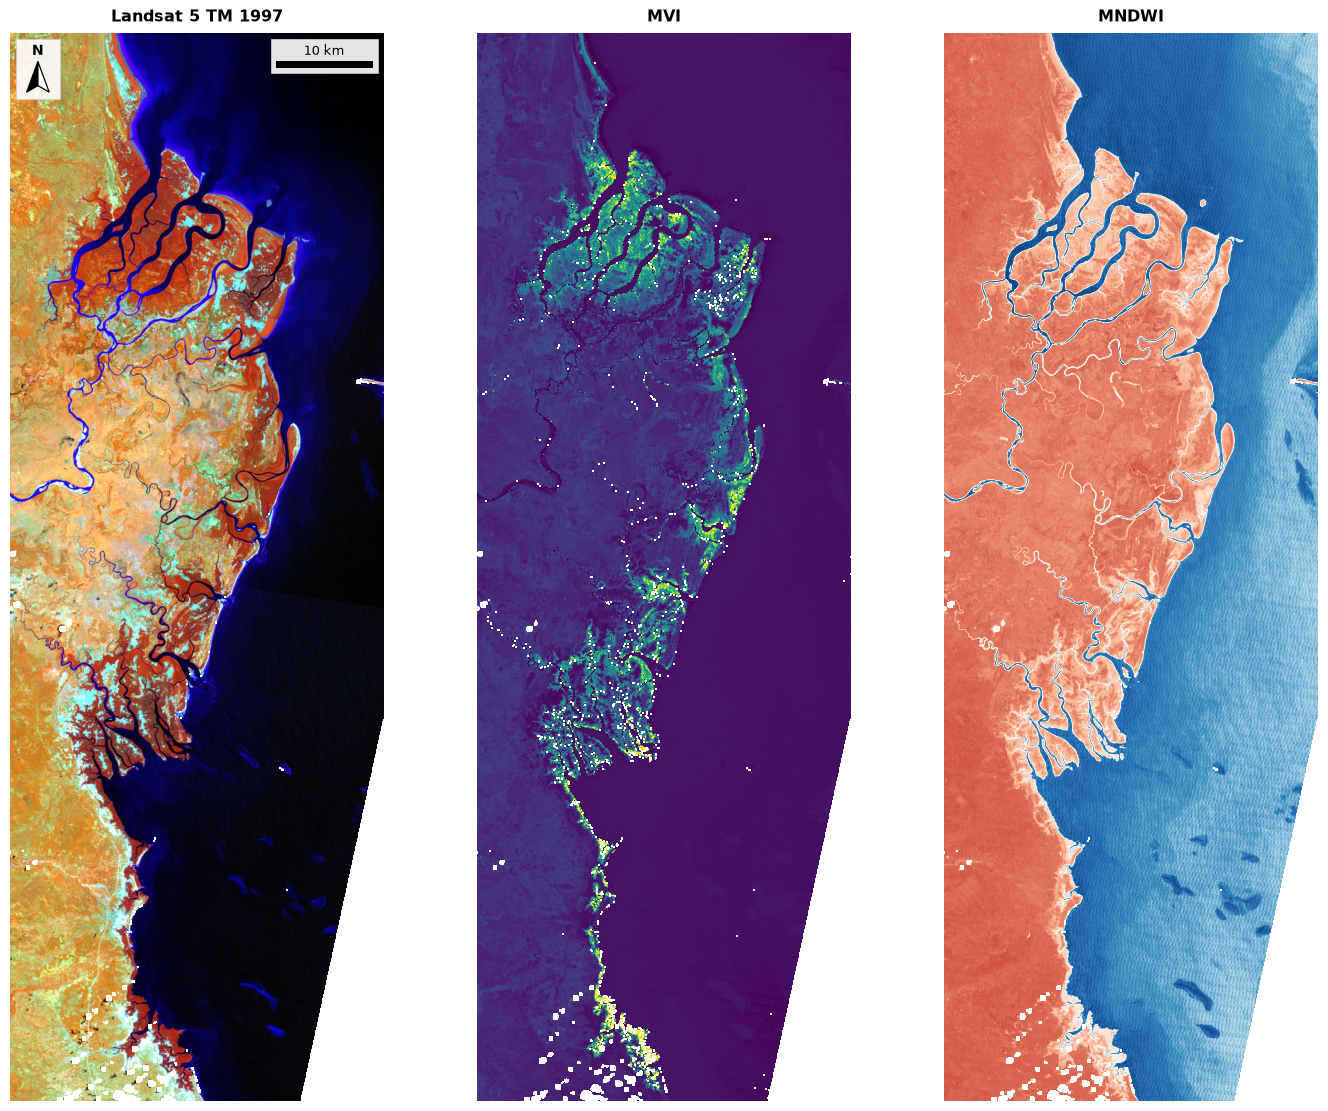

In [6]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_img, bands=[4, 5, 3], title="Landsat 5 TM 1997"),
        MapPanel("cmap", idx_img, bands=[indices.index("MVI") + 1], title="MVI",
                 cmap_name="viridis", vmin=0, vmax=15),
        MapPanel("cmap", idx_img, bands=[indices.index("MNDWI") + 1], title="MNDWI",
                 cmap_name="RdBu", vmin=-1, vmax=1),
    ],
    figsize=(14, 11),
)

## 4. Classification Set-up and Samples

The `ClassificationConfig` lists two images: the six reflectance bands and the eleven indices. The band names become the column names of the sample tables and the feature names of the classifier, so all 17 features are extracted together. The classes, output IDs and colours are the same as in the baseline notebook.

In [7]:
img_band_info = [
    ImageBandInfo(input_img, name="sref", bands=[1, 2, 3, 4, 5, 6], band_names=refl_band_names),
    ImageBandInfo(idx_img, name="idx", bands=list(range(1, len(indices) + 1)), band_names=indices),
]

class_info = {
    "mangroves": ClassInfoObj(
        out_id=1, vec_file=os.path.join(train_dir, "mangroves.geojson"), colour=(0, 255, 0)
    ),
    "other_terrestrial": ClassInfoObj(
        out_id=2, vec_file=os.path.join(train_dir, "other_terrestrial.geojson"), colour=(180, 180, 180)
    ),
    "water": ClassInfoObj(
        out_id=3, vec_file=os.path.join(train_dir, "water.geojson"), colour=(0, 0, 255)
    ),
}

cls_cfg = ClassificationConfig(img_band_info, class_info)
cls_cfg_file = os.path.join(out_dir, "cls_config.json")
write_cls_config(cls_cfg_file, cls_cfg)

all_feats = cls_cfg.get_band_names()
print(all_feats)

['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2', 'NDVI', 'EVI', 'SAVI', 'NDWI', 'MNDWI', 'NDMI', 'NBR', 'CMRI', 'MVI', 'MMRI', 'AWEI_sh']


Extract and split the samples with the same settings as the baseline notebook: each class is capped at 20,000 pixels, of which 20 % are kept for validation (used to tune the classifier) and 20 % for testing (an independent accuracy check).

In [8]:
train_file = os.path.join(out_dir, "train.parquet")
valid_file = os.path.join(out_dir, "valid.parquet")
test_file = os.path.join(out_dir, "test.parquet")

train_df, test_df, valid_df = extract_and_split_class_samples(
    cls_cfg,
    test_prop=0.2,
    valid_prop=0.2,
    out_train_file=train_file,
    out_test_file=test_file,
    out_valid_file=valid_file,
    max_cls_smpls=20000,
    rnd_seed=rnd_seed,
    use_pbar=False,
)
for name, smpls_df in (("train", train_df), ("valid", valid_df), ("test", test_df)):
    print(name, smpls_df["class_name"].value_counts().to_dict())

train {'mangroves': 12000, 'other_terrestrial': 12000, 'water': 12000}
valid {'mangroves': 4000, 'other_terrestrial': 4000, 'water': 4000}
test {'mangroves': 4000, 'other_terrestrial': 4000, 'water': 4000}


> **Spatial autocorrelation:** the pixels are split at random, so pixels from the same training polygon end up in the training, validation and testing sets. Neighbouring pixels are very similar, so the validation and testing accuracies will be optimistic, and they will make different feature sets look more similar than they are. Splitting by polygon (`group_col`) gives a more honest estimate but needs many polygons per class; see `03_supervised_pixel_classification`, section 3.5.

## 5. Explore the Features

Before selecting features it is worth looking at them. `comparison_box_plots` draws the distribution of each feature for each class (violin plots by default); here we show four of the 17 plots it writes (look in `outputs/mangrove_xgb_interp/feature_plots` for the others).

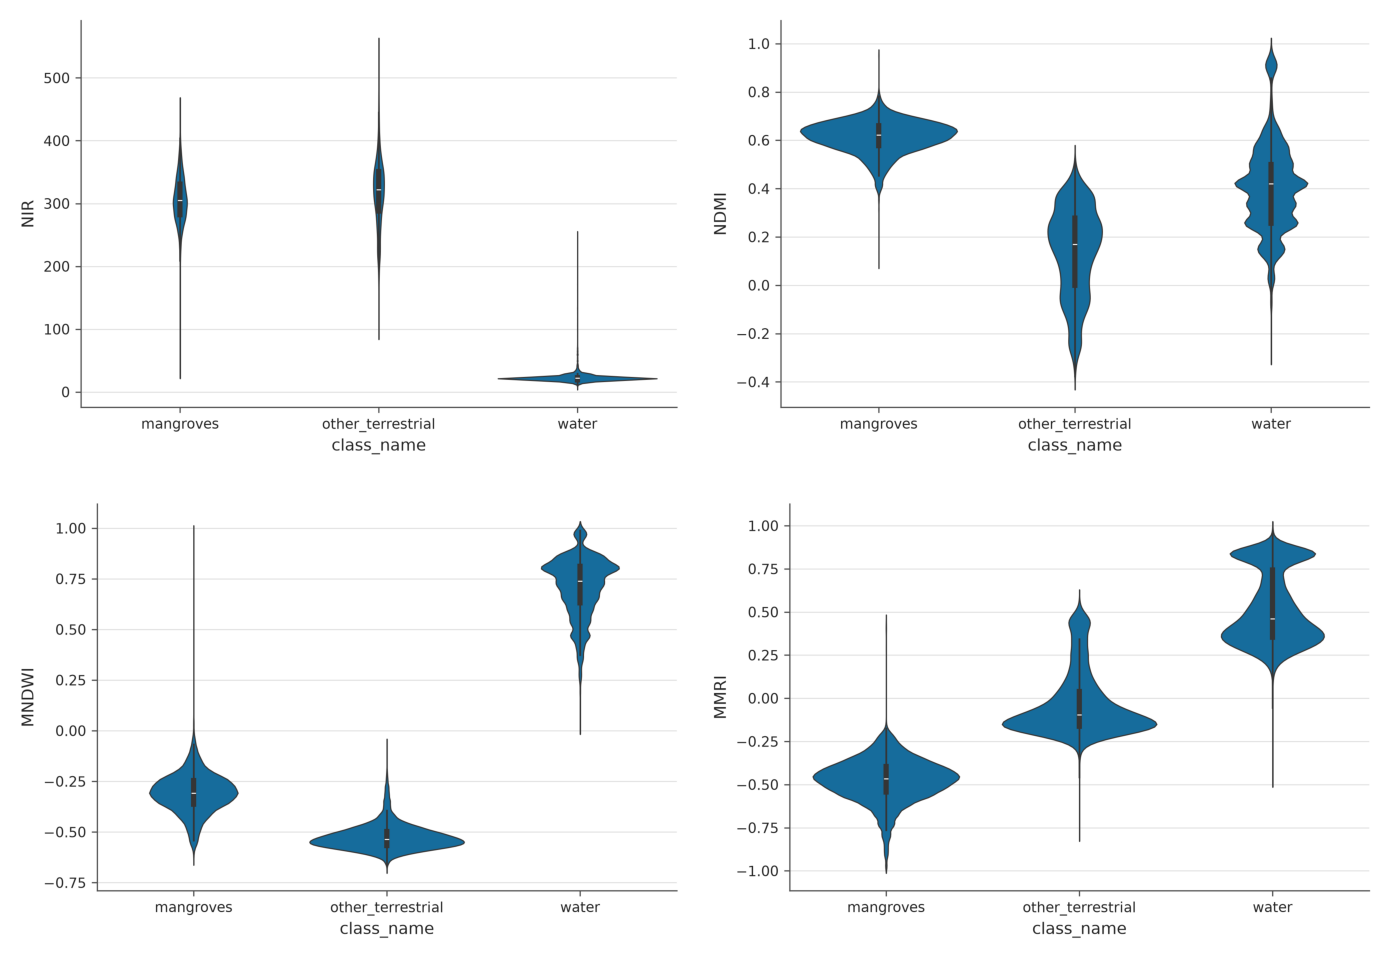

In [9]:
box_dir = os.path.join(out_dir, "feature_plots")
box_files = cf.comparison_box_plots(train_file, cls_cfg, out_dir=box_dir, use_pbar=False)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
for ax, feat in zip(axs.flatten(), ["NIR", "NDMI", "MNDWI", "MMRI"]):
    ax.imshow(plt.imread(os.path.join(box_dir, f"{feat}_comp_plot.png")))
    ax.axis("off")
plt.tight_layout()
plt.show()

Water is easy to separate: it has very low NIR reflectance and high MNDWI. The scientifically interesting pair is **mangroves vs other terrestrial land cover**, which overlap almost completely in NIR (both are vegetated). NDMI separates them much better (mangroves have more canopy water), and mangroves have a higher MNDWI and a lower MMRI than the other terrestrial land cover (a wetter substrate and a darker SWIR1 response).

The MVI plot is not shown: a few mangrove samples have MVI values of ±300 (see section 11.5), which squash the violins into lines. The medians per class show that MVI separates the two vegetated classes strongly (8.0 for mangroves, 1.6 for other terrestrial and 0.8 for water):

In [10]:
train_df.groupby("class_name")[all_feats].median().T.round(2)

class_name,mangroves,other_terrestrial,water
Blue,20.00,38.00,58.00
Green,36.00,68.00,67.00
Red,23.00,66.00,37.00
NIR,305.00,322.00,22.00
SWIR1,69.00,227.00,9.00
SWIR2,26.00,119.00,9.00
NDVI,0.86,0.66,-0.25
EVI,0.54,0.44,-0.05
SAVI,0.51,0.42,-0.04
NDWI,-0.78,-0.65,0.49


Next, the Spearman (rank) correlation between the features. Spearman correlation is used because several of the features are strongly skewed (e.g., MVI) and the relationships need not be linear.

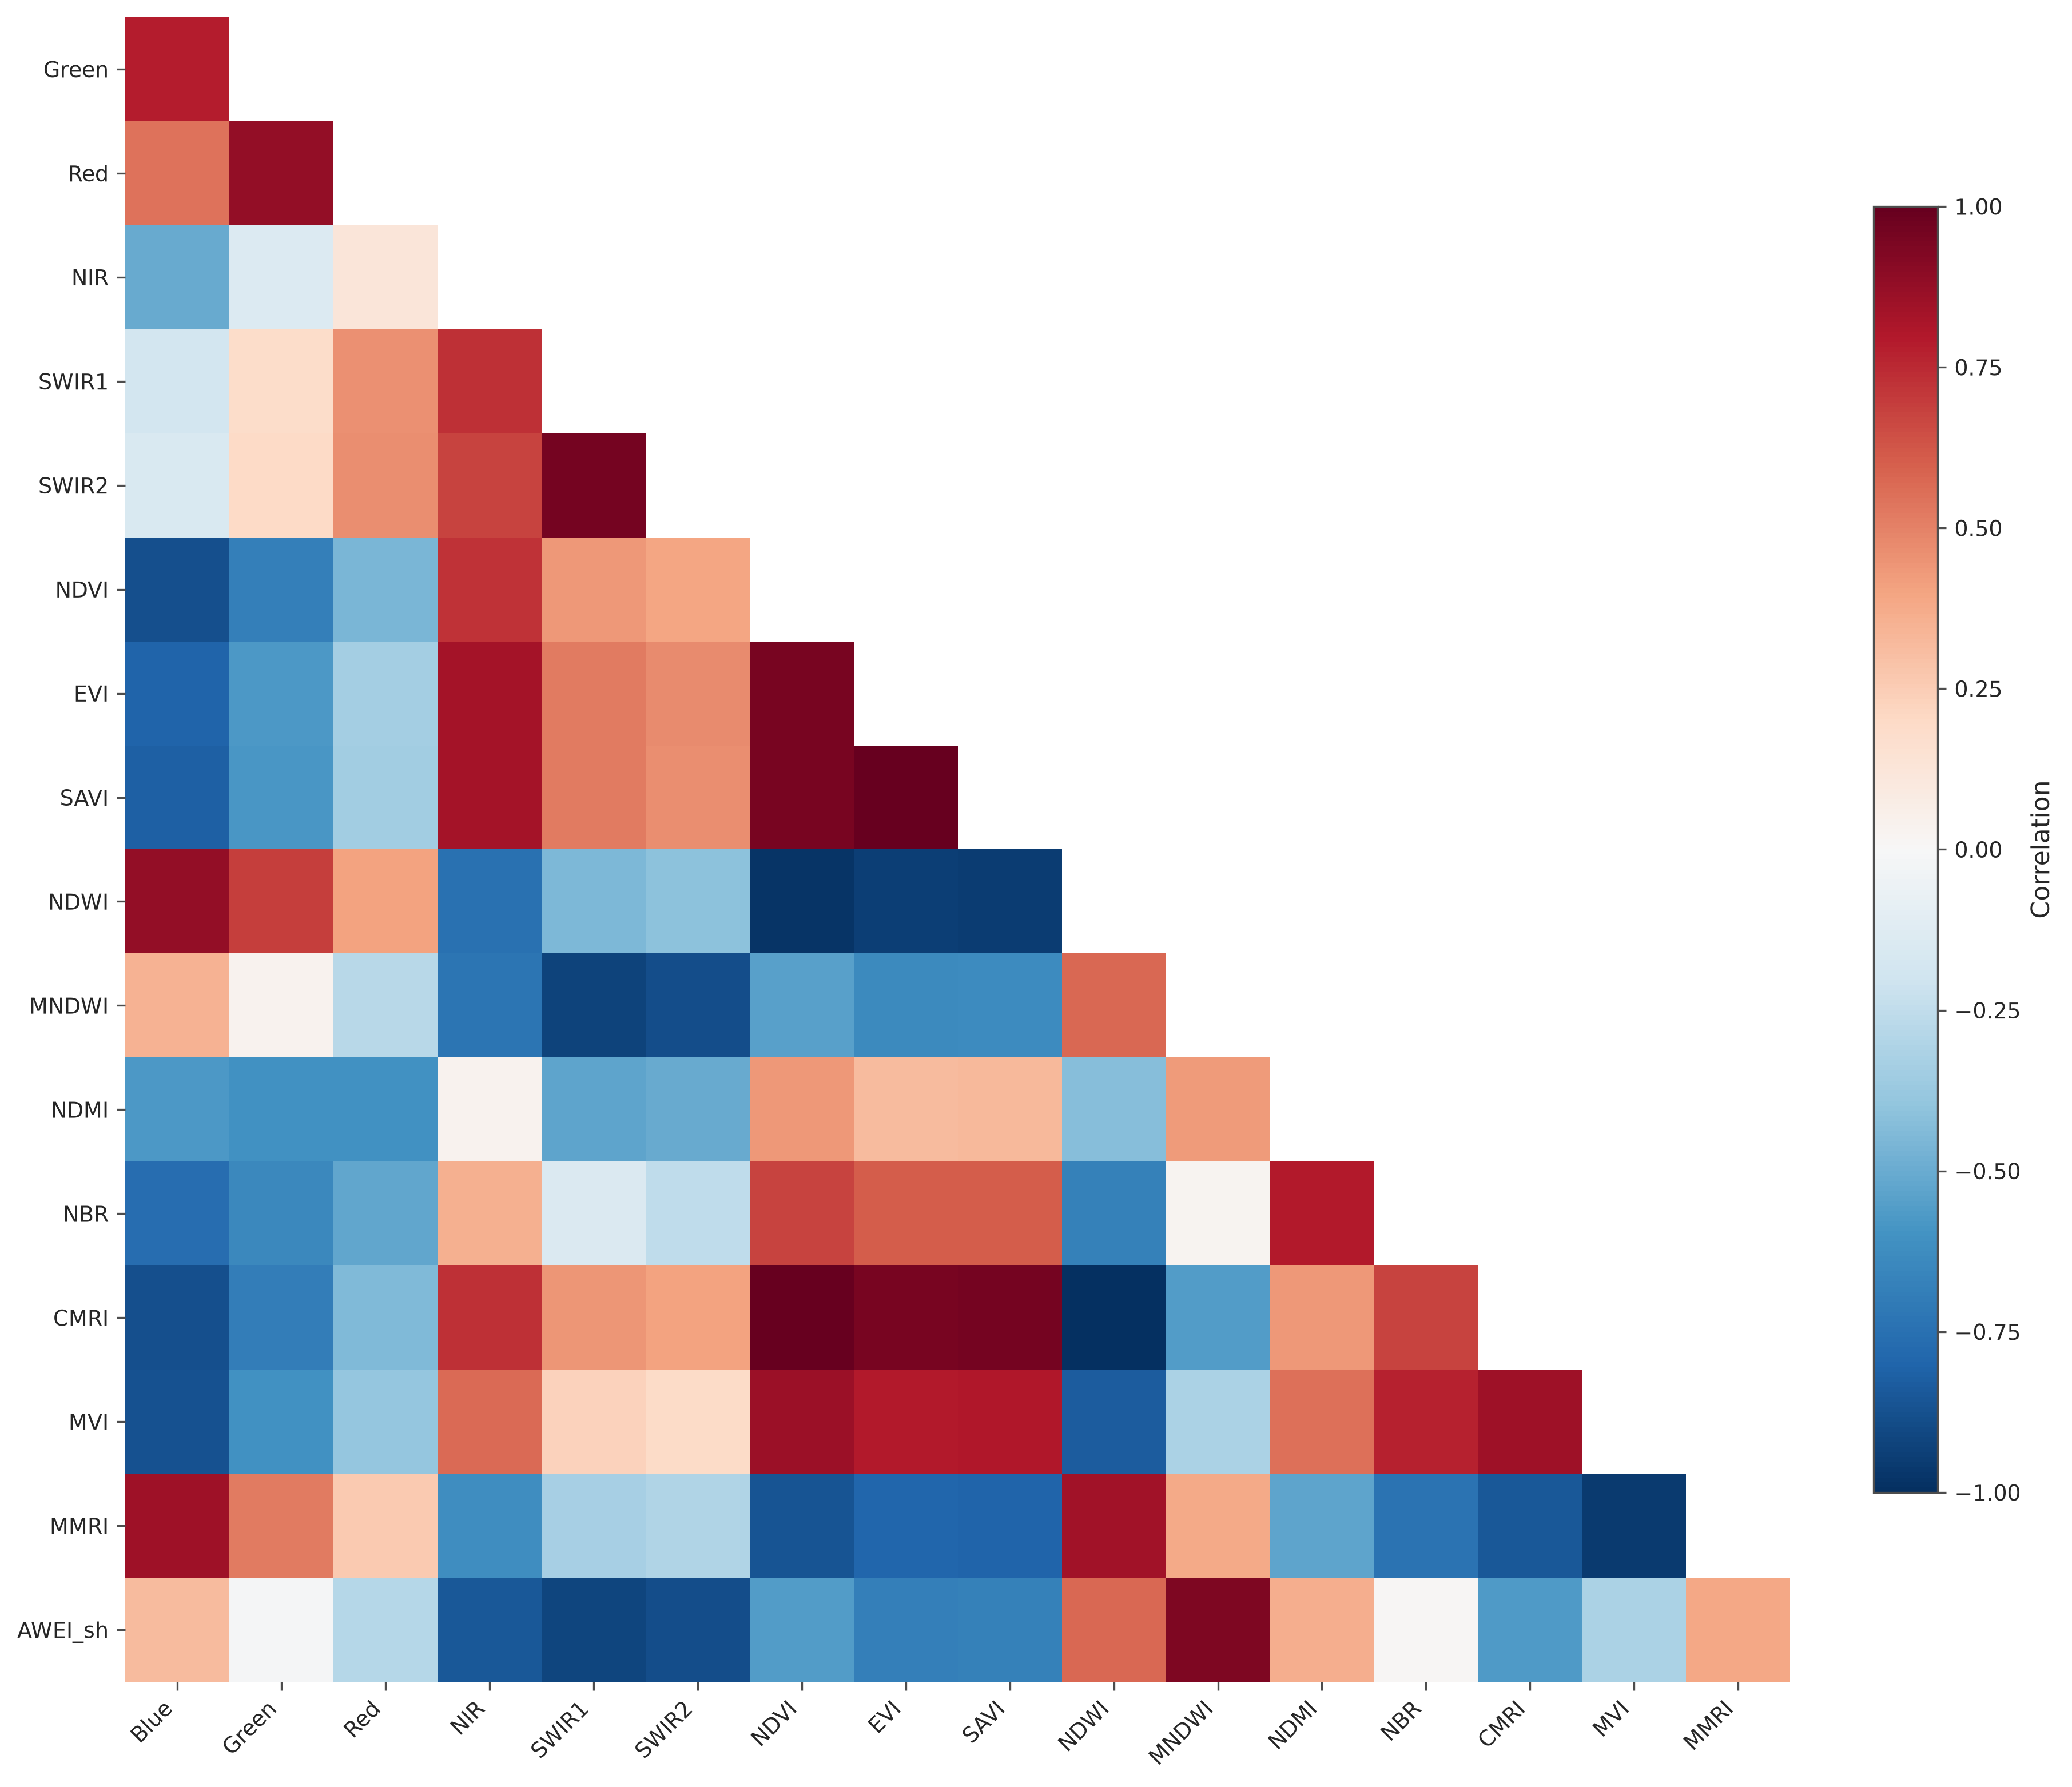

In [11]:
corr_df = cf.correlation_matrix(
    train_file,
    cls_cfg,
    method="spearman",
    out_corr_file=os.path.join(out_dir, "correlation_matrix.csv"),
    out_plt_file=os.path.join(out_dir, "correlation_matrix.png"),
    fig_width=12,
    fig_height=11,
)
display(Image(filename=os.path.join(out_dir, "correlation_matrix.png"), width=750))

In [12]:
# Pairs of features with an absolute Spearman correlation of at least 0.95.
upper = corr_df.where(numpy.triu(numpy.ones(corr_df.shape, dtype=bool), k=1))
high_corr = upper.stack()
high_corr = high_corr[high_corr.abs() >= 0.95].sort_values(key=abs, ascending=False)
high_corr.round(3).to_frame("spearman_r")

,,spearman_r
EVI,SAVI,0.997
NDVI,CMRI,0.995
NDWI,CMRI,-0.993
NDVI,NDWI,-0.977
SWIR1,SWIR2,0.959
MVI,MMRI,-0.954
SAVI,CMRI,0.954
NDVI,SAVI,0.953


As expected, there are groups of almost interchangeable features: NDVI, CMRI, NDWI (negatively), SAVI and EVI carry nearly the same information, and the visible bands are strongly correlated with each other.

The variance inflation factor (VIF) measures how well each feature can be predicted from *all* the others (see `05_regression/02_feature_selection`). Values above 10 are usually taken to indicate problematic multicollinearity.

In [13]:
vif_all = cf.calc_vif_multicollinearity(
    train_file, cls_cfg, out_vif_file=os.path.join(out_dir, "vif_all_features.csv")
)
vif_all.sort_values().to_frame("VIF").round(1)

Calculating VIF for 17 predictors variables...


,VIF
MVI,1.600000e+00
NBR,7.100000e+00
MMRI,2.270000e+01
NDMI,3.080000e+01
Red,2.494000e+02
MNDWI,3.451000e+02
EVI,4.007000e+02
SAVI,2.482300e+03
SWIR2,4.560919e+09
Blue,1.341365e+10


Most VIFs are enormous. Some features are (almost) exact linear combinations of others: AWEI_sh is a weighted sum of five of the bands, so it can be predicted perfectly from them. Only MVI and NBR have VIFs below 10.

## 6. Feature Selection

Feature selection uses **only the training samples**. The validation samples are used to tune the classifier and the testing samples to assess it; if they were used to choose the features, information from them would leak into the model and the accuracy estimates would be inflated.

Two stages are used:

1. **Redundancy:** remove features which are (nearly) duplicates of others, using VIF.
2. **Relevance:** keep the remaining features which carry real information about the classes, using BorutaShap, cross-checked with recursive feature elimination (RFE).

### 6.1 Redundancy: VIF

`select_features_vif` repeatedly removes the feature with the highest VIF until all the remaining features have a VIF below the threshold (10, the usual rule of thumb). It prints the number of features at each step.

In [14]:
vif_feats, vif_sel = cf.select_features_vif(
    train_file, cls_cfg, vif_threshold=10.0, return_vif=True,
    out_vif_file=os.path.join(out_dir, "vif_selected_features.csv"),
)
print("Kept:   ", vif_feats)
print("Removed:", [feat for feat in all_feats if feat not in vif_feats])
vif_sel.round(2).to_frame("VIF")

Calculating VIF for 17 predictors variables...
Calculating VIF for 16 predictors variables...


Calculating VIF for 15 predictors variables...
Calculating VIF for 14 predictors variables...


Calculating VIF for 13 predictors variables...
Calculating VIF for 12 predictors variables...
Calculating VIF for 11 predictors variables...


Calculating VIF for 10 predictors variables...
Calculating VIF for 9 predictors variables...
Calculating VIF for 8 predictors variables...
Calculating VIF for 7 predictors variables...
Kept:    ['Blue', 'Red', 'NDVI', 'NDMI', 'NBR', 'MVI', 'MMRI']
Removed: ['Green', 'NIR', 'SWIR1', 'SWIR2', 'EVI', 'SAVI', 'NDWI', 'MNDWI', 'CMRI', 'AWEI_sh']


,VIF
Blue,8.41
Red,5.98
NDVI,4.97
NDMI,4.15
NBR,5.06
MVI,1.37
MMRI,6.94


Ten of the 17 features were removed, leaving seven with VIFs between 1.4 and 8.4. Note what VIF does and does not do:

* It removes the feature with the highest VIF at each step, so which member of a group of near-duplicates survives is somewhat arbitrary: NDVI was kept and SAVI, EVI, CMRI and NDWI were removed, but NDVI is not "better" than them.
* Information is not lost just because a feature was removed. None of the SWIR bands was kept, but SWIR1 is still in NDMI, MVI and MMRI, and SWIR2 in NBR. MNDWI was removed, but MMRI is calculated from MNDWI and NDVI.
* VIF does not look at the classes at all: it only measures redundancy, not whether a feature is useful. That is the job of the next step.

### 6.2 Relevance: BorutaShap

**Boruta** (Kursa & Rudnicki, 2010) adds a shuffled copy (a "shadow") of every feature to the data. Shadow features have the same distributions as the real ones but no relationship with the classes. A model is trained repeatedly and a real feature is *confirmed* if its importance beats the best shadow feature significantly more often than chance (a binomial test), *rejected* if it is significantly worse, and *tentative* otherwise. **BorutaShap** uses SHAP values (section 10.2) as the importance measure, which is more reliable than the split-based importance of tree models.

Boruta is an *all-relevant* method: it keeps every feature that carries information, even if another feature carries the same information. This is why it is run after the VIF step.

We use an XGBoost classifier with fixed, moderate parameters (the parameters are optimised later, on the selected features). `subsample_n_smpls` limits the number of samples used to calculate the SHAP values in each trial, to keep the run time down.

In [15]:
xgb_template = xgboost.XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=rnd_seed,
)

fs_dir = os.path.join(out_dir, "feature_selection")
boruta_feats, boruta_df = cf.select_features_boruta_shap(
    cls_cfg,
    train_file,
    sk_classifier=xgb_template,
    feature_cols=vif_feats,
    n_trials=20,
    subsample_n_smpls=2000,
    rnd_seed=rnd_seed,
    out_scores_file=os.path.join(fs_dir, "boruta_shap_vif_feats.csv"),
    out_plot_file=os.path.join(fs_dir, "boruta_shap_vif_feats.png"),
    use_pbar=False,
    return_scores=True,
)
print("Selected:", boruta_feats)
boruta_df[["feature", "decision", "median_importance", "rank"]]

Selected: ['Blue', 'Red', 'NDVI', 'NDMI', 'NBR', 'MVI', 'MMRI']


,feature,decision,median_importance,rank
0,NDVI,Confirmed,1.628821,1
1,MVI,Confirmed,0.829469,2
2,NDMI,Confirmed,0.715723,3
3,MMRI,Confirmed,0.602570,4
4,Red,Confirmed,0.549401,5
5,NBR,Confirmed,0.210396,6
6,Blue,Confirmed,0.157678,7


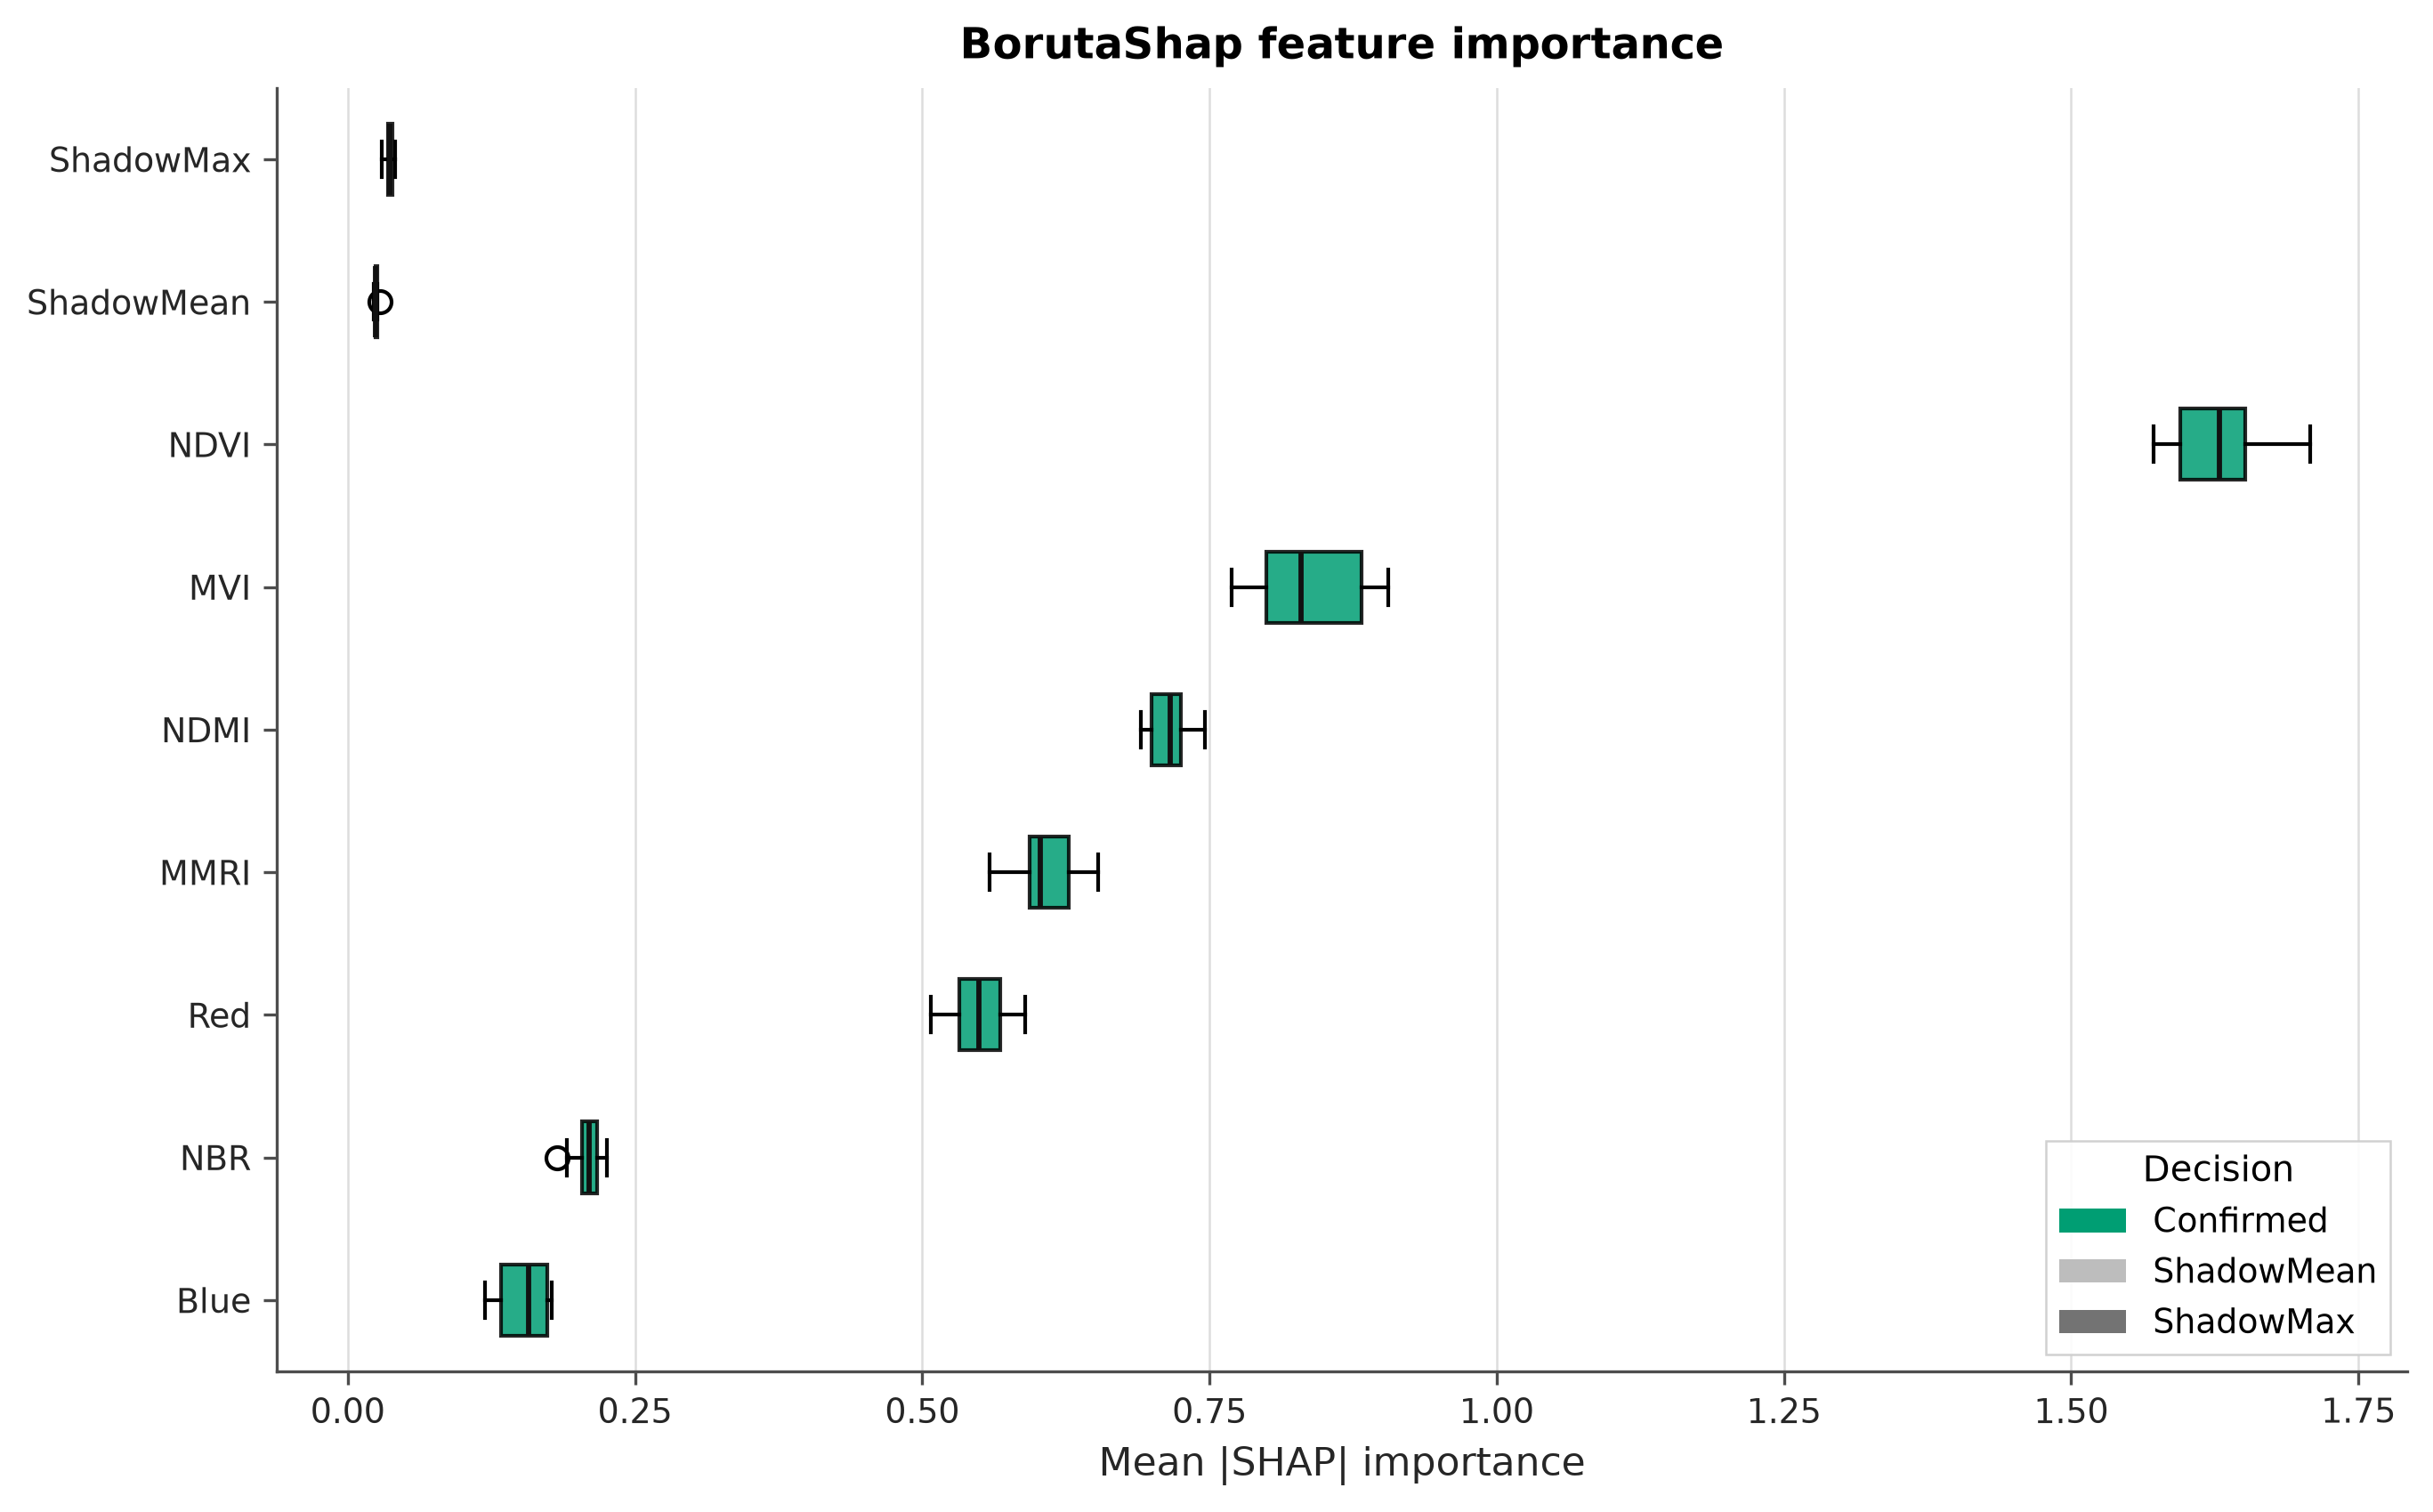

In [16]:
display(Image(filename=os.path.join(fs_dir, "boruta_shap_vif_feats.png"), width=700))

All seven features are **confirmed**: each was more important than the best shadow feature in significantly more trials than expected by chance. NDVI has the highest median importance, followed by MVI, NDMI and MMRI; Blue and NBR are the least important but still clearly better than noise. With 36,000 training samples and a strong signal it is common for Boruta to confirm almost everything; it is a test of "carries some information", not of "is needed".

To see why the redundancy step is needed, the next cell runs BorutaShap on all 17 features.

In [17]:
boruta_all_feats, boruta_all_df = cf.select_features_boruta_shap(
    cls_cfg,
    train_file,
    sk_classifier=xgb_template,
    n_trials=20,
    subsample_n_smpls=2000,
    rnd_seed=rnd_seed,
    use_pbar=False,
    return_scores=True,
)
print(f"{len(boruta_all_feats)} of {len(all_feats)} features selected")
boruta_all_df[["feature", "decision", "median_importance", "rank"]]

17 of 17 features selected


,feature,decision,median_importance,rank
0,SAVI,Confirmed,0.939911,1
1,MVI,Confirmed,0.722153,2
2,SWIR1,Confirmed,0.580816,3
3,SWIR2,Confirmed,0.527277,4
4,NIR,Confirmed,0.518454,5
5,MNDWI,Confirmed,0.254477,6
6,MMRI,Confirmed,0.228992,7
7,NDMI,Confirmed,0.187315,8
8,Blue,Confirmed,0.172724,9
9,NBR,Confirmed,0.121633,10


All 17 features are confirmed. This is the all-relevant behaviour of Boruta: each of the near-duplicate features (e.g., NDVI, SAVI, EVI and CMRI) carries real information about the classes, so each passes the test, even though the model only needs one of them. Note also how the importance is spread unpredictably across correlated features: SAVI is ranked 1st and NDVI 12th, although they have a Spearman correlation of 0.95. This is why the importance of correlated features is hard to interpret, and why the redundancy step comes first.

### 6.3 Cross-check: Recursive Feature Elimination

Recursive feature elimination (RFE; Guyon et al., 2002) is a *minimal-optimal* method: it trains the model, removes the least important feature, and repeats. With `use_cv=True` (RFECV), the number of features is chosen by 5-fold cross-validation on the training samples, here using the macro F1 score.

Selected: ['Blue', 'Red', 'NDVI', 'NDMI', 'NBR', 'MVI', 'MMRI']


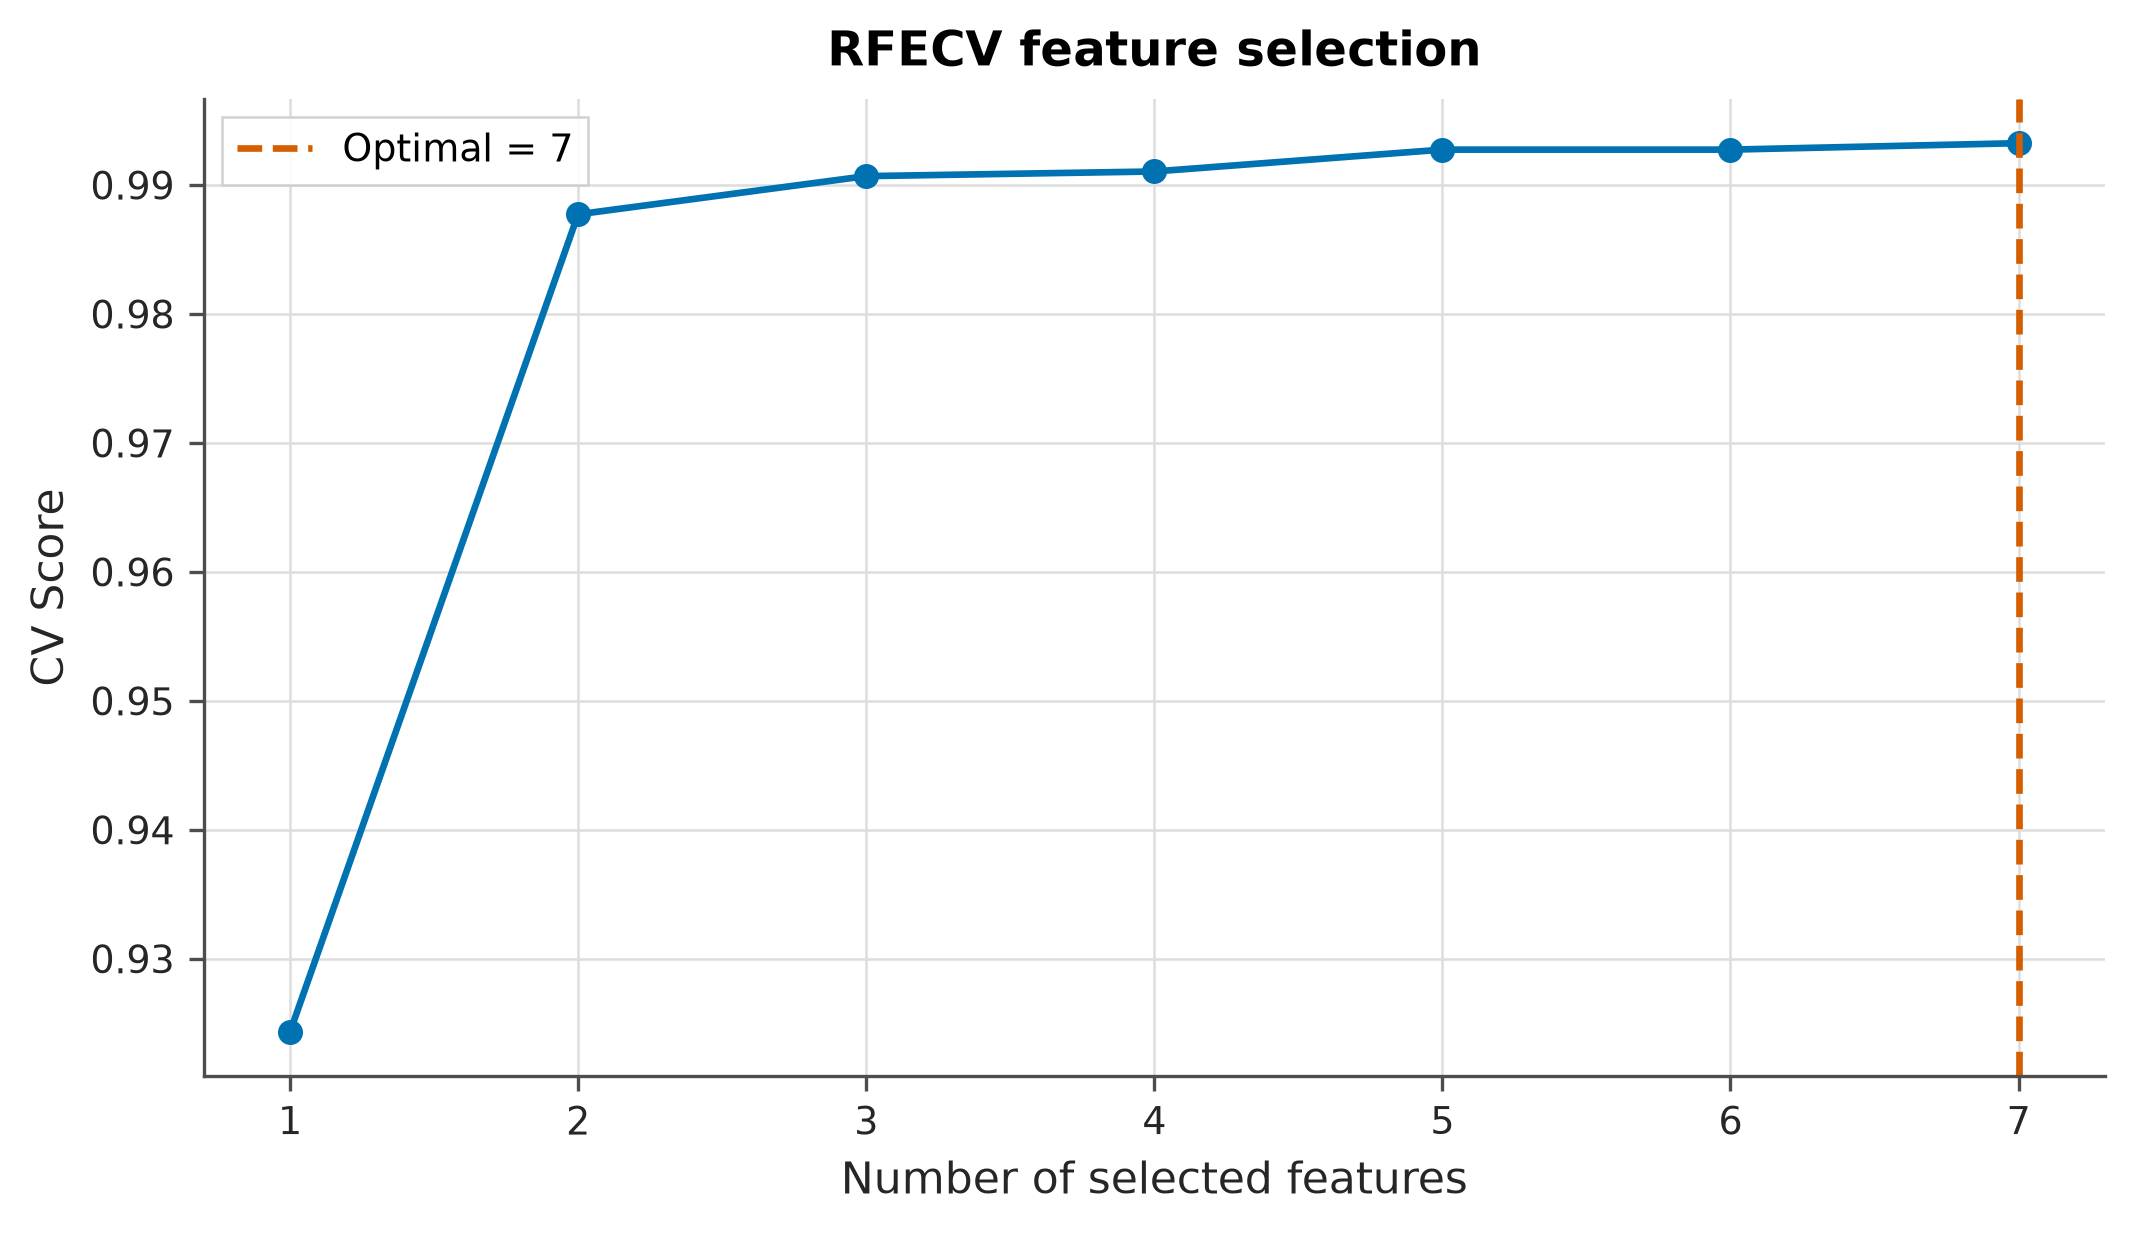

In [18]:
rfe_feats, rfe_df = cf.select_features_rfe(
    cls_cfg,
    xgb_template,
    train_file,
    feature_cols=vif_feats,
    use_cv=True,
    cv=5,
    scoring="f1_macro",
    rnd_seed=rnd_seed,
    out_scores_file=os.path.join(fs_dir, "rfecv_vif_feats.csv"),
    out_cv_plot=os.path.join(fs_dir, "rfecv_vif_feats.png"),
    return_scores=True,
)
print("Selected:", rfe_feats)
display(Image(filename=os.path.join(fs_dir, "rfecv_vif_feats.png"), width=600))

### 6.4 The Final Feature Set

BorutaShap confirmed all seven features left by the VIF step, and RFECV also kept all seven. The RFECV plot shows why the two methods agree here: one feature gives a cross-validated macro F1 score of 0.924, two features 0.988, and from three to seven features the score only rises from about 0.991 to 0.993. The extra features add little, but they do not hurt either, and the RFECV optimum is all seven.

We therefore use the seven features: **Blue, Red, NDVI, NDMI, NBR, MVI and MMRI**. They include a water-sensitive feature (MMRI, which contains MNDWI) and three moisture-sensitive features (NDMI, NBR and MVI), the properties we expected to matter for mangroves (section 3). Had the methods disagreed, we would have preferred the BorutaShap set, as long as it kept at least one water- and one moisture-sensitive feature, as it is less likely to drop a feature only because a correlated feature is present.

In [19]:
sel_feats = list(boruta_feats)

# Check the selection keeps at least one water-sensitive and one
# moisture-sensitive feature.
water_feats = {"NDWI", "MNDWI", "MMRI", "AWEI_sh", "CMRI"}
moisture_feats = {"NDMI", "NBR", "MVI", "SWIR1", "SWIR2"}
print("Water-sensitive:   ", sorted(water_feats.intersection(sel_feats)))
print("Moisture-sensitive:", sorted(moisture_feats.intersection(sel_feats)))
print("Agrees with RFECV: ", sorted(sel_feats) == sorted(rfe_feats))

with open(os.path.join(out_dir, "selected_features.json"), "w") as f:
    json.dump(sel_feats, f, indent=4)
print(sel_feats)

Water-sensitive:    ['MMRI']
Moisture-sensitive: ['MVI', 'NBR', 'NDMI']
Agrees with RFECV:  True
['Blue', 'Red', 'NDVI', 'NDMI', 'NBR', 'MVI', 'MMRI']


## 7. Optimise the XGBoost Parameters

As in the baseline notebook, the XGBoost parameters are optimised with a Bayesian search ([Optuna](https://optuna.org)): each trial trains a model with a different set of parameters on the training samples and scores it (accuracy) on the validation samples, with early stopping on the validation samples. `feature_cols` restricts the model to the selected features. The parameters searched, and their ranges, are:

In [20]:
pandas.DataFrame(cxgb.get_xgboost_optuna_param_space()).T

,type,low,high,step,log
n_estimators,int,50,500,25,NaN
learning_rate,float,0.01,0.3,NaN,True
max_depth,int,3,10,NaN,NaN
min_child_weight,int,1,5,NaN,NaN
gamma,float,0.0001,1.0,NaN,True
subsample,float,0.5,1.0,NaN,NaN
colsample_bytree,float,0.5,1.0,NaN,NaN
reg_alpha,float,0.0001,1.0,NaN,True
reg_lambda,float,0.0001,10.0,NaN,True


What the main parameters control:

* `n_estimators`: the number of trees. More trees fit the training data more closely; early stopping on the validation samples stops adding trees when they no longer help.
* `learning_rate`: how much each new tree corrects the previous ones. Smaller values need more trees but usually generalise better.
* `max_depth`: the depth of each tree, i.e., how many features can interact within one tree. Deeper trees capture more complex interactions but overfit more easily.
* `min_child_weight`: the minimum amount of data (strictly, hessian weight) in a leaf; larger values make the model more conservative.
* `subsample` and `colsample_bytree`: the fractions of the samples and of the features used to build each tree. Randomising these reduces overfitting.
* `gamma`: the minimum loss reduction needed to make a further split.
* `reg_alpha` and `reg_lambda`: L1 and L2 regularisation of the leaf weights.

Thirty trials are used to keep the run time short; with your own data you would usually use more (e.g., 100).

In [21]:
n_opt_trials = 30

xgb_sel_opt, opt_results = cxgb.optimise_xgboost_multiclass_classifier(
    cls_cfg,
    train_file,
    valid_data=valid_file,
    feature_cols=sel_feats,
    n_trials=n_opt_trials,
    early_stopping_rounds=20,
    rnd_seed=rnd_seed,
    return_results=True,
    use_pbar=False,
)
print(f"Best validation accuracy: {opt_results['best_score']:.4f}")
pandas.Series(opt_results["best_params"]).to_frame("value")

Best validation accuracy: 0.9936


,value
n_estimators,250.000000
learning_rate,0.026927
max_depth,7.000000
min_child_weight,1.000000
gamma,0.001474
subsample,0.683181
colsample_bytree,0.728035
reg_alpha,0.138262
reg_lambda,0.000996


## 8. Train, Test and Compare

### 8.1 Train the Final Classifier

The final model is trained with the optimised parameters on the selected features, saved, and its accuracy calculated for the training and (independent) testing samples.

In [22]:
sel_mdl_file = os.path.join(out_dir, "xgb_selected_feats_mdl.json")
xgb_sel_mdl, sel_metrics = cxgb.train_xgboost_multiclass_classifier(
    cls_cfg,
    train_file,
    test_data=test_file,
    xgb_classifier=xgb_sel_opt,
    feature_cols=sel_feats,
    out_model_file=sel_mdl_file,
)
pandas.Series(sel_metrics).round(4).to_frame("selected features")

,selected features
train_accuracy,0.9974
train_bal_accuracy,0.9974
train_f1_macro,0.9974
train_cohen_kappa,0.9960
test_accuracy,0.9933
test_bal_accuracy,0.9933
test_f1_macro,0.9933
test_cohen_kappa,0.9900


The confusion matrix of the testing samples shows where the errors are (rows: reference class; columns: predicted class). The classifier was trained on the internal class IDs (0, 1, 2), which are mapped back to the class names here.

In [23]:
id_to_name = test_df.drop_duplicates("internal_cls_id").set_index("internal_cls_id")["class_name"].sort_index()
test_pred = xgb_sel_mdl.predict(test_df[sel_feats])
cm_df = pandas.DataFrame(
    confusion_matrix(test_df["internal_cls_id"], test_pred, labels=id_to_name.index),
    index=[f"ref: {n}" for n in id_to_name],
    columns=[f"pred: {n}" for n in id_to_name],
)
cm_df["producer_acc"] = numpy.diag(cm_df.values) / cm_df.sum(axis=1)
cm_df

,pred: mangroves,pred: other_terrestrial,pred: water,producer_acc
ref: mangroves,3952,45,3,0.988
ref: other_terrestrial,32,3968,0,0.992
ref: water,0,0,4000,1.000


### 8.2 What Did the Indices and the Feature Selection Buy?

To answer this, two more models are optimised and trained with the same budget (30 trials): one on the six reflectance bands only (as in the baseline notebook) and one on all 17 features.

In [24]:
feat_sets = {
    "bands only (6)": refl_band_names,
    "all features (17)": all_feats,
}
cmp_metrics = {f"selected ({len(sel_feats)})": sel_metrics}
cmp_mdls = dict()
for set_name, set_feats in feat_sets.items():
    set_opt = cxgb.optimise_xgboost_multiclass_classifier(
        cls_cfg,
        train_file,
        valid_data=valid_file,
        feature_cols=set_feats,
        n_trials=n_opt_trials,
        early_stopping_rounds=20,
        rnd_seed=rnd_seed,
        use_pbar=False,
    )
    set_mdl_file = os.path.join(out_dir, f"xgb_{set_name.split()[0]}_mdl.json")
    cmp_mdls[set_name], cmp_metrics[set_name] = cxgb.train_xgboost_multiclass_classifier(
        cls_cfg,
        train_file,
        test_data=test_file,
        xgb_classifier=set_opt,
        feature_cols=set_feats,
        out_model_file=set_mdl_file,
    )
bands_mdl_file = os.path.join(out_dir, "xgb_bands_mdl.json")

pandas.DataFrame(cmp_metrics).T[
    ["train_accuracy", "test_accuracy", "test_f1_macro", "test_cohen_kappa"]
].round(4)

,train_accuracy,test_accuracy,test_f1_macro,test_cohen_kappa
selected (7),0.9974,0.9933,0.9933,0.9900
bands only (6),0.9980,0.9940,0.9940,0.9910
all features (17),0.9999,0.9943,0.9943,0.9915


All three models have a test accuracy of 99.3 – 99.4 %, and the differences between them (at most 0.1 percentage points, about 12 of the 12,000 test pixels) are too small to mean anything. **On this test set, neither the indices nor the feature selection improved the accuracy.** This is a useful, honest result rather than a failure:

* The problem is easy: Water is classified perfectly by every model, and the two vegetated classes are well separated in this scene.
* The test pixels come from the same polygons as the training pixels (random pixel split), so all three models are tested on very familiar data and their accuracies are close to the ceiling. A polygon-grouped test would separate them better.
* XGBoost can learn useful band combinations itself from 36,000 samples.

What the indices and the selection *did* buy is a model with fewer, less redundant, physically meaningful inputs, which (as section 10 shows) is much easier to interpret, and which may generalise better to other dates, where the relationships between raw reflectances change more than those of normalised indices. That last point cannot be tested with this data.

## 9. Apply the Classifier

### 9.1 Analysis Mask

As in the baseline notebook, mangroves are only classified within a mangrove habitat mask (similar to that used by the Global Mangrove Watch; Bunting et al., 2018), combined with the valid-data mask of the image.

In [25]:
# Rasterise the habitat polygons on to the image pixel grid.
hab_msk_img = os.path.join(out_dir, "mangrove_habitat.tif")
rasterise_vec_lyr(hab_vec_file, None, input_img, hab_msk_img, burn_val=1, use_pbar=False)

# Valid-data mask of the image (1 where the image has data).
vld_msk_img = os.path.join(out_dir, "LS5TM_19970716_vmsk.tif")
gen_valid_mask(input_img, vld_msk_img, no_data_val=0.0, use_pbar=False)

# Pixels which are valid and within the habitat mask.
analysis_msk_img = os.path.join(out_dir, "LS5TM_19970716_vmsk_mng_hab.tif")
band_maths(
    analysis_msk_img,
    "(vld==1)&&(hab==1)?1:0",
    [BandDefn("vld", vld_msk_img, 1), BandDefn("hab", hab_msk_img, 1)],
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)
set_thematic_classes(analysis_msk_img, {1: ("Mangrove habitat", (0, 160, 0))})

### 9.2 Matching the Model Features to the Image Bands

The `ClassificationConfig` lists all 17 bands, but the model was trained on only some of them. An XGBoost model trained on a pandas `DataFrame` stores the names (and order) of its features in `feature_names_in_`, and `apply_xgboost_multiclass_classifier` uses them to pick and order the image bands: only the bands the model needs are read, in the model's order, and an error is raised if a feature is not in the configuration. So the same configuration can be used for all three models. We can check the names match:

In [26]:
print("Model features: ", list(xgb_sel_mdl.feature_names_in_))
print("In cls_cfg:     ", [feat in all_feats for feat in xgb_sel_mdl.feature_names_in_])

Model features:  [np.str_('Blue'), np.str_('Red'), np.str_('NDVI'), np.str_('NDMI'), np.str_('NBR'), np.str_('MVI'), np.str_('MMRI')]
In cls_cfg:      [True, True, True, True, True, True, True]


### 9.3 Classify the Image

The final model is applied within the analysis mask. As well as the classification, a score image is written with the probability of each class for each pixel. The bands-only model is also applied so the two maps can be compared.

In [27]:
cls_info = {cls.out_id: (name, cls.colour) for name, cls in class_info.items()}

sel_cls_img = os.path.join(out_dir, "LS5TM_19970716_cls_xgb_selected.tif")
sel_scr_img = os.path.join(out_dir, "LS5TM_19970716_cls_xgb_selected_score.tif")
cxgb.apply_xgboost_multiclass_classifier(
    cls_cfg,
    sel_mdl_file,
    analysis_msk_img,
    1,
    output_img=sel_cls_img,
    out_score_img=sel_scr_img,
    use_pbar=False,
)
set_thematic_classes(sel_cls_img, cls_info)

bands_cls_img = os.path.join(out_dir, "LS5TM_19970716_cls_xgb_bands.tif")
cxgb.apply_xgboost_multiclass_classifier(
    cls_cfg,
    bands_mdl_file,
    analysis_msk_img,
    1,
    output_img=bands_cls_img,
    use_pbar=False,
)
set_thematic_classes(bands_cls_img, cls_info)

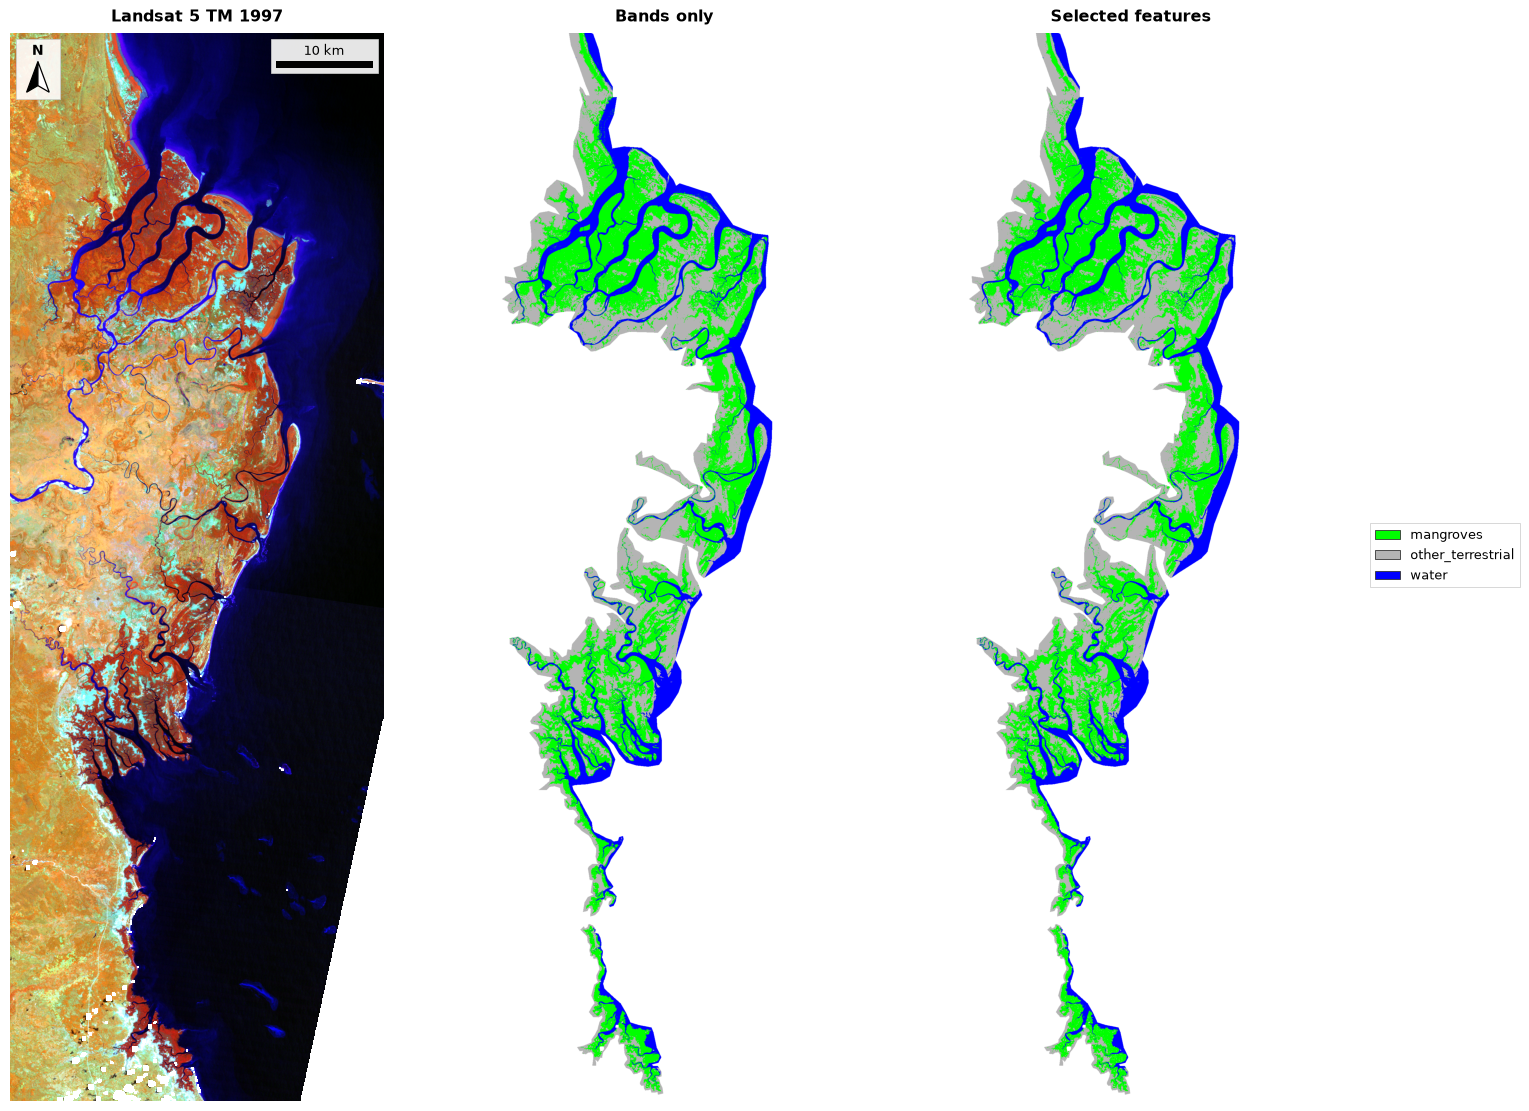

In [28]:
cls_panels = [
    MapPanel("rgb", input_img, bands=[4, 5, 3], title="Landsat 5 TM 1997"),
    MapPanel("thematic", bands_cls_img, title="Bands only"),
    MapPanel("thematic", sel_cls_img, title="Selected features"),
]
fig, axs = create_map_panels(cls_panels, figsize=(14, 11))

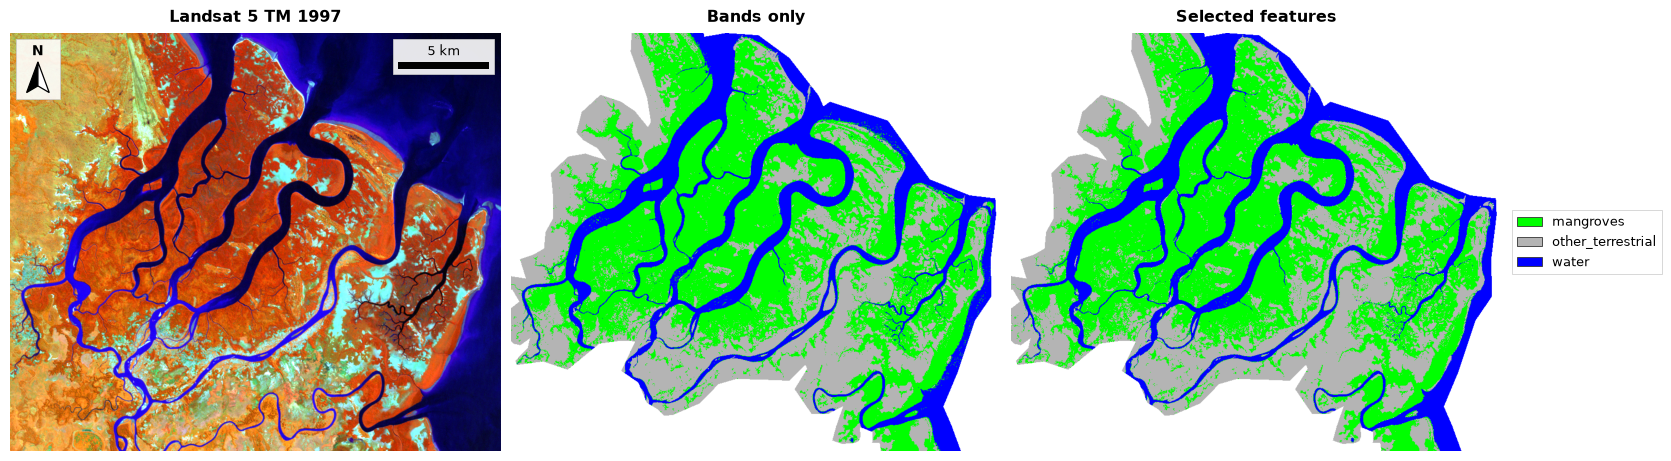

In [29]:
sub_bbox = [523000, 550000, -877000, -854000]
fig, axs = create_map_panels(cls_panels, bbox=sub_bbox, figsize=(15, 6))

The probability of the mangrove class (the first band of the score image) shows where the model is confident:

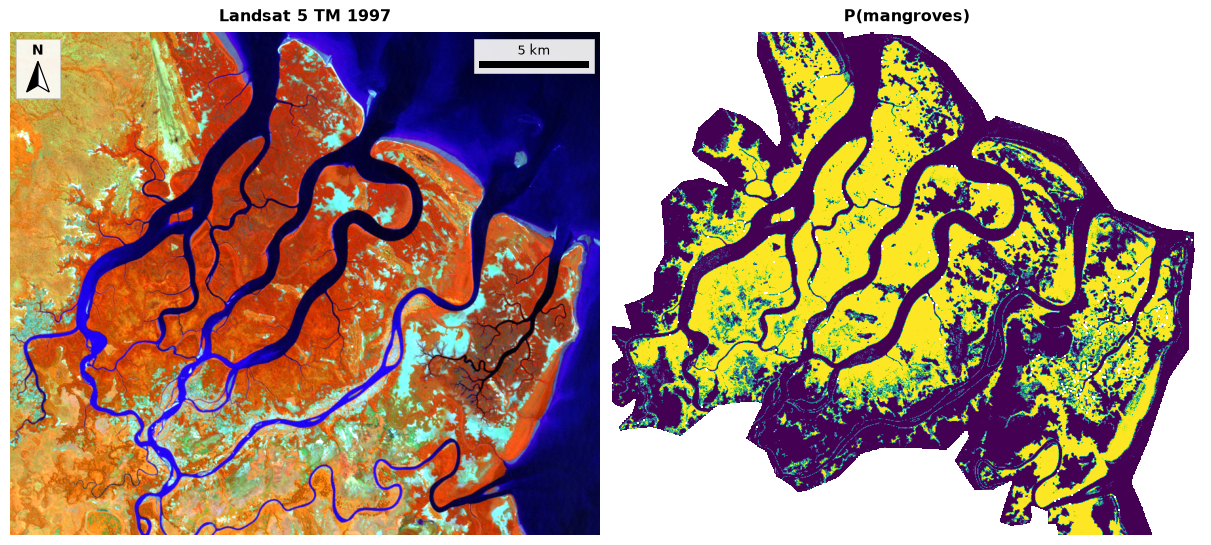

In [30]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_img, bands=[4, 5, 3], title="Landsat 5 TM 1997"),
        MapPanel("cmap", sel_scr_img, bands=[1], title="P(mangroves)",
                 cmap_name="viridis", vmin=0, vmax=1),
    ],
    bbox=sub_bbox,
    figsize=(12, 6),
)

The area of each class in the two classifications, and the proportion of the analysed pixels on which they agree:

In [31]:
with rasterio.open(bands_cls_img) as ds:
    bands_cls = ds.read(1)
    pxl_area_ha = abs(ds.transform.a * ds.transform.e) / 10000
with rasterio.open(sel_cls_img) as ds:
    sel_cls = ds.read(1)

area_rows = dict()
for out_id, (name, _) in cls_info.items():
    area_rows[name] = {
        "bands only (ha)": (bands_cls == out_id).sum() * pxl_area_ha,
        "selected (ha)": (sel_cls == out_id).sum() * pxl_area_ha,
    }
area_df = pandas.DataFrame(area_rows).T
area_df["difference (%)"] = 100 * (area_df["selected (ha)"] - area_df["bands only (ha)"]) / area_df["bands only (ha)"]

classified = (bands_cls > 0) & (sel_cls > 0)
disagree = classified & (bands_cls != sel_cls)
print(f"Agreement: {100 * (bands_cls[classified] == sel_cls[classified]).mean():.2f} % of the classified pixels")

# Are the disagreements on the edges of the class regions? A pixel is on an
# edge if one of its neighbours has a different class (in the selected-features map).
on_edge = numpy.zeros(sel_cls.shape, dtype=bool)
for out_id in cls_info:
    cls_msk = sel_cls == out_id
    on_edge |= cls_msk & ~ndimage.binary_erosion(cls_msk)
print(f"{100 * (disagree & on_edge).sum() / disagree.sum():.1f} % of the disagreeing pixels are on a class edge")
area_df.round(1)

Agreement: 96.06 % of the classified pixels
84.4 % of the disagreeing pixels are on a class edge


,bands only (ha),selected (ha),difference (%)
mangroves,38253.5,38023.2,-0.6
other_terrestrial,34605.5,35231.8,1.8
water,18881.6,18385.9,-2.6


The two classifications agree on 96 % of the classified pixels, and the class areas differ by less than 3 %. The disagreements are not random: more than 80 % of them (see the output above) are on the edge of a class region in the selected-features map, i.e., mixed pixels on the boundaries between mangroves, other land cover and water, where a small change in the model can flip the class. The agreement over the whole image (96 %) is lower than either model's test accuracy (99.3 %+), which is another sign that the test pixels (from the centres of homogeneous training polygons) are easier than a typical pixel in the image.

## 10. Interpret the Model

The test accuracy tells us *how well* the model works on samples like the training data; the methods below tell us *how* it works. Each answers a slightly different question, so they are used together:

| Method | Question | Data used |
|---|---|---|
| Permutation importance | How much does the accuracy drop if a feature's values are shuffled? | Testing samples |
| SHAP | How much did each feature push each individual prediction up or down? | Training samples (a subset) |
| Sobol sensitivity (SALib) | How much of the variation in a class probability is due to each feature (alone and through interactions)? | Values sampled across the feature ranges |
| Response curves | How does a class probability change as one feature changes, with the others held fixed? | A grid across one feature's range |

All of them use the final model (`xgb_sel_mdl`) and the selected features.

### 10.1 Permutation Importance

Permutation importance is a model-agnostic reference: each feature in turn is shuffled (breaking its relationship with the class), the accuracy on the testing samples is recalculated, and the drop in accuracy is the feature's importance. It is repeated 10 times to give a mean and standard deviation. A feature whose information is also available from a correlated feature can get a low importance, because the model can partly fall back on the other feature.

In [32]:
interp_dir = os.path.join(out_dir, "interpretation")
perm_imp_df = cf.calc_feature_importance(
    cls_cfg,
    xgb_sel_mdl,
    test_file,
    feature_cols=sel_feats,
    method="permutation",
    scoring="accuracy",
    n_repeats=10,
    rnd_seed=rnd_seed,
    out_importance_file=os.path.join(interp_dir, "permutation_importance.csv"),
    out_plot_file=os.path.join(interp_dir, "permutation_importance.png"),
)
perm_imp_df.round(4)

,feature,importance_mean,importance_std,rank
0,NDVI,0.2100,0.0040,1
1,NDMI,0.0259,0.0013,2
2,Red,0.0190,0.0009,3
3,MVI,0.0093,0.0006,4
4,MMRI,0.0018,0.0004,5
5,Blue,0.0010,0.0004,6
6,NBR,-0.0001,0.0002,7


NDVI dominates: shuffling it reduces the accuracy by 21 percentage points, mostly because NDVI is what separates water from land (water has negative NDVI). NDMI, Red and MVI follow with drops of 1 – 3 points; shuffling MMRI or Blue costs less than 0.2 points, and shuffling NBR makes no difference at all. A small permutation importance does not mean a feature is useless: MVI and MMRI are strongly correlated (Spearman r = −0.95), so when one is shuffled the model can still rely on the other.

### 10.2 SHAP

SHAP (SHapley Additive exPlanations; Lundberg & Lee, 2017) splits each individual prediction into a contribution from each feature, using Shapley values from cooperative game theory. For a tree model the values can be calculated exactly and quickly (`use_tree_explainer=True`; Lundberg et al., 2020).

For a multi-class XGBoost model there is one set of SHAP values **per class**, on the scale of the model's raw output for that class (the log-odds, or margin, before the softmax converts the outputs to probabilities). For each pixel and class:

`model output = expected value + sum of the SHAP values of the features`

So a SHAP value of +2 for MVI means that this pixel's MVI value raised the mangrove log-odds by 2 compared with the average prediction. Positive values push towards the class, negative values away from it. The SHAP values are calculated for a random subset of 3,000 training samples.

In [33]:
shap_df = cf.calc_shap_feature_contributions(
    cls_cfg,
    xgb_sel_mdl,
    train_file,
    feature_cols=sel_feats,
    use_tree_explainer=True,
    subsample_n_smpls=3000,
    rnd_seed=rnd_seed,
    shap_summary_plot=os.path.join(interp_dir, "shap_summary_all_classes.png"),
    out_shap_file=os.path.join(interp_dir, "shap_mean_abs.csv"),
)
shap_df.round(3)

,feature,mean_abs_shap,mean_abs_shap_mangroves,mean_abs_shap_other_terrestrial,mean_abs_shap_water
0,NDVI,1.156,0.077,1.104,2.286
1,MVI,0.768,1.775,0.383,0.146
2,MMRI,0.656,0.665,0.319,0.986
3,NDMI,0.613,0.333,1.368,0.138
4,Red,0.378,0.234,0.641,0.258
5,NBR,0.150,0.286,0.144,0.019
6,Blue,0.139,0.292,0.082,0.043


The table gives the mean absolute SHAP value of each feature, overall and per class; the plot stacks the per-class values.

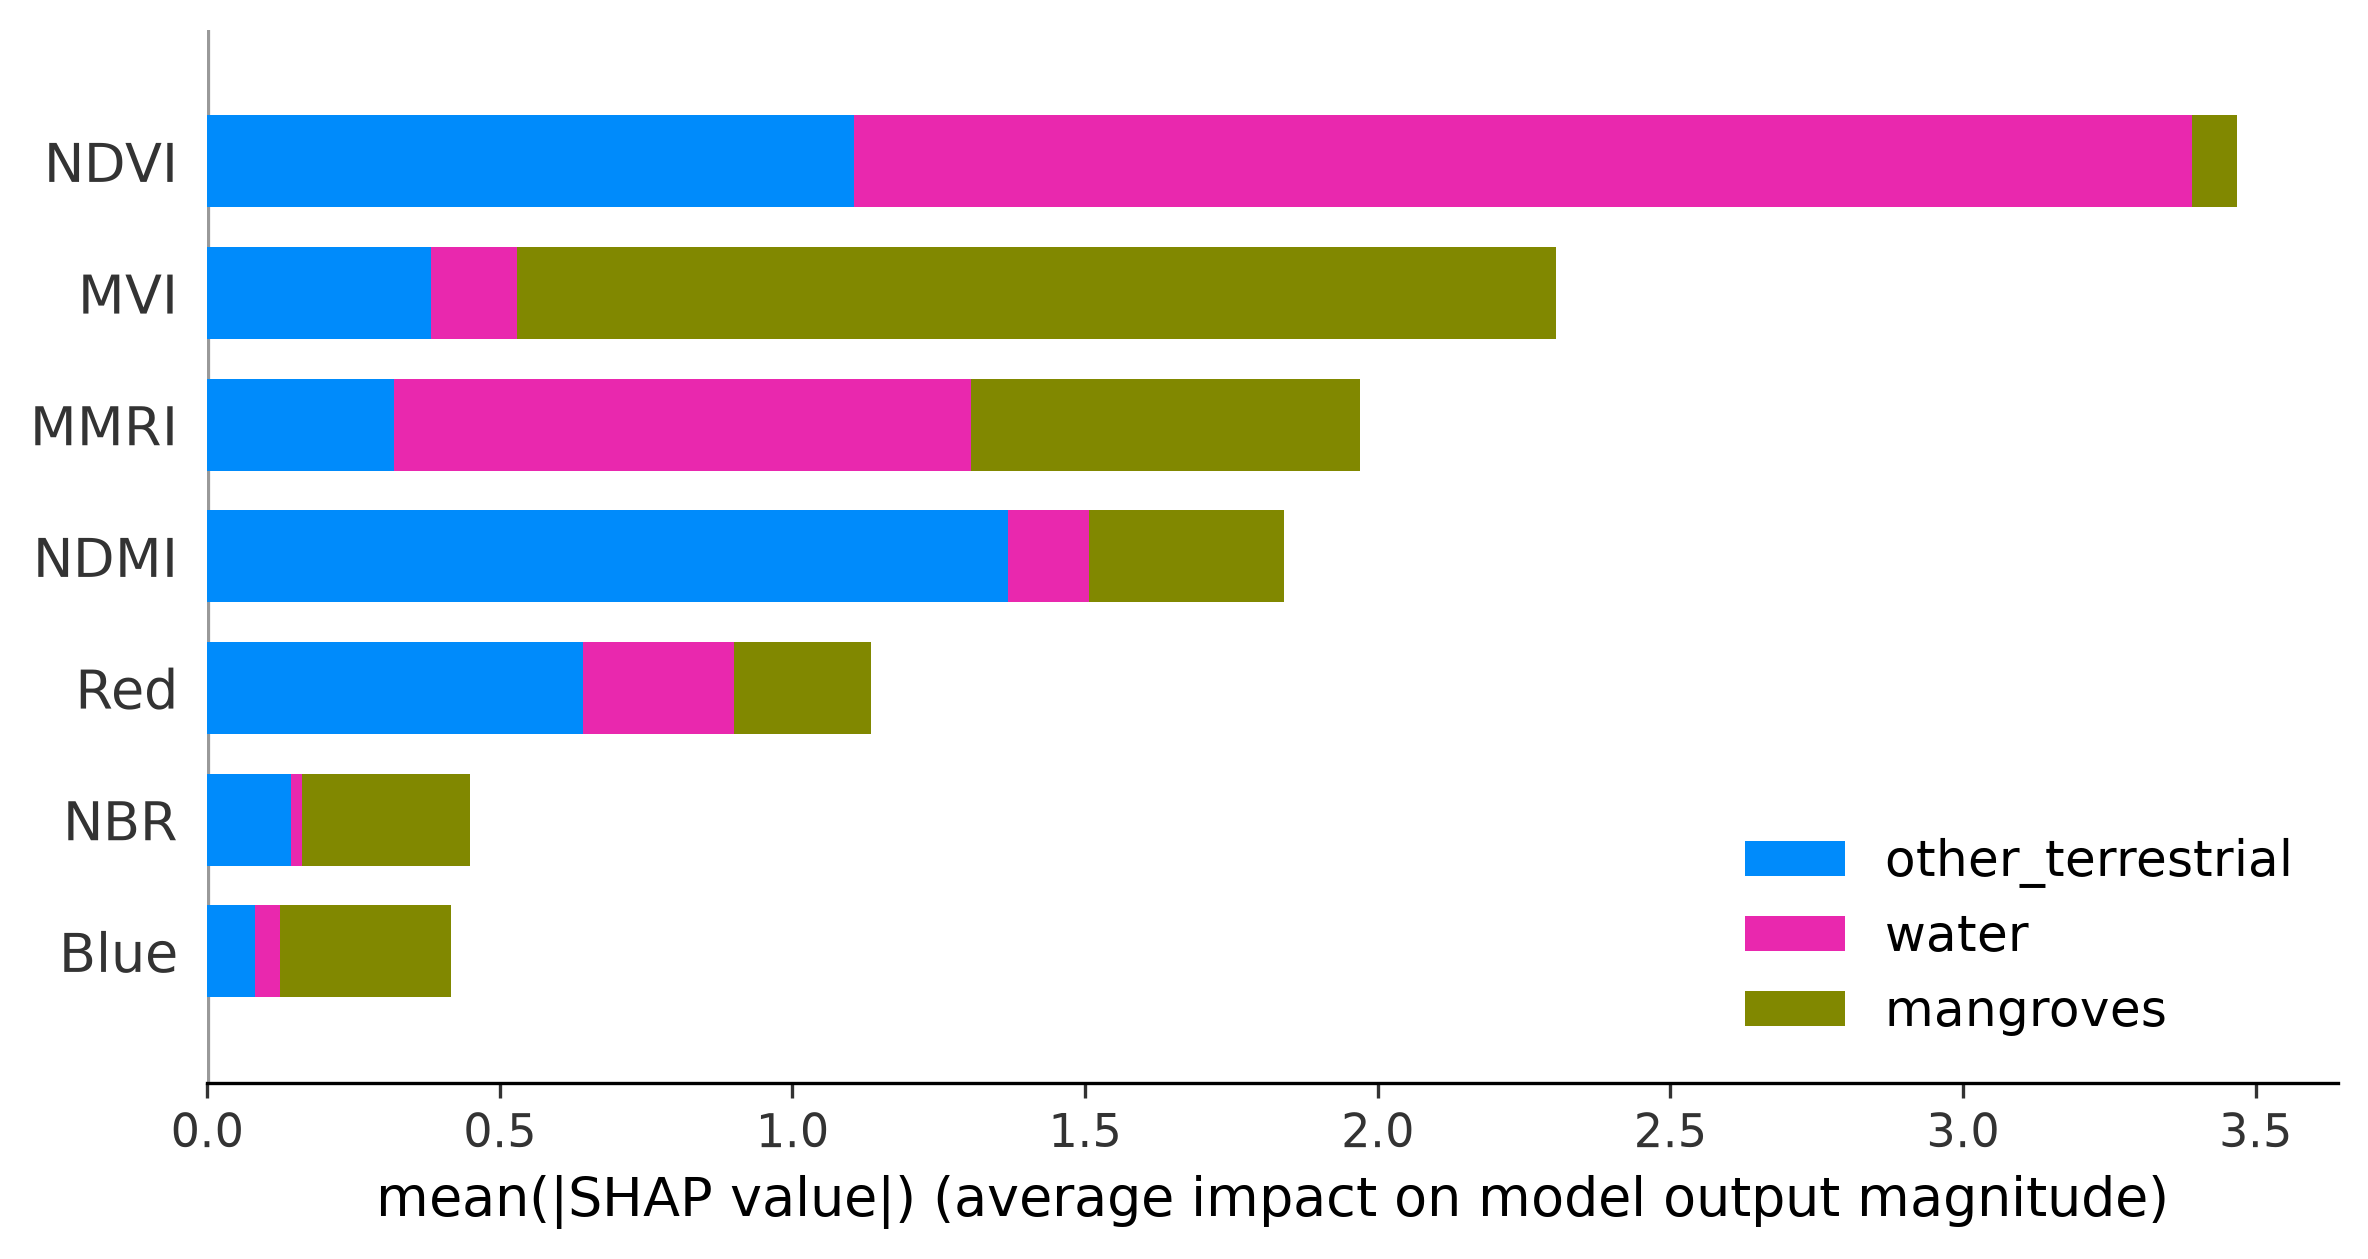

In [34]:
display(Image(filename=os.path.join(interp_dir, "shap_summary_all_classes.png"), width=700))

The per-class columns show that the features do different jobs:

* **Water** is driven mainly by NDVI (mean |SHAP| = 2.3) and MMRI (1.0).
* **Other-Terrestrial** by NDMI (1.4) and NDVI (1.1), then Red (0.6).
* **Mangroves** by MVI (1.8), far ahead of MMRI (0.7) and NDMI (0.3). NDVI contributes almost nothing to the mangrove output (0.08): NDVI tells the model that a pixel is vegetated, but not *which* vegetation it is.

Setting `target_class` gives the SHAP values of one class. The summary ("beeswarm") plot for mangroves has one point per sample for each feature: the position is the SHAP value and the colour is the feature value (red is high, blue is low). The scatter plots then show the SHAP value against the feature value for the top four features.

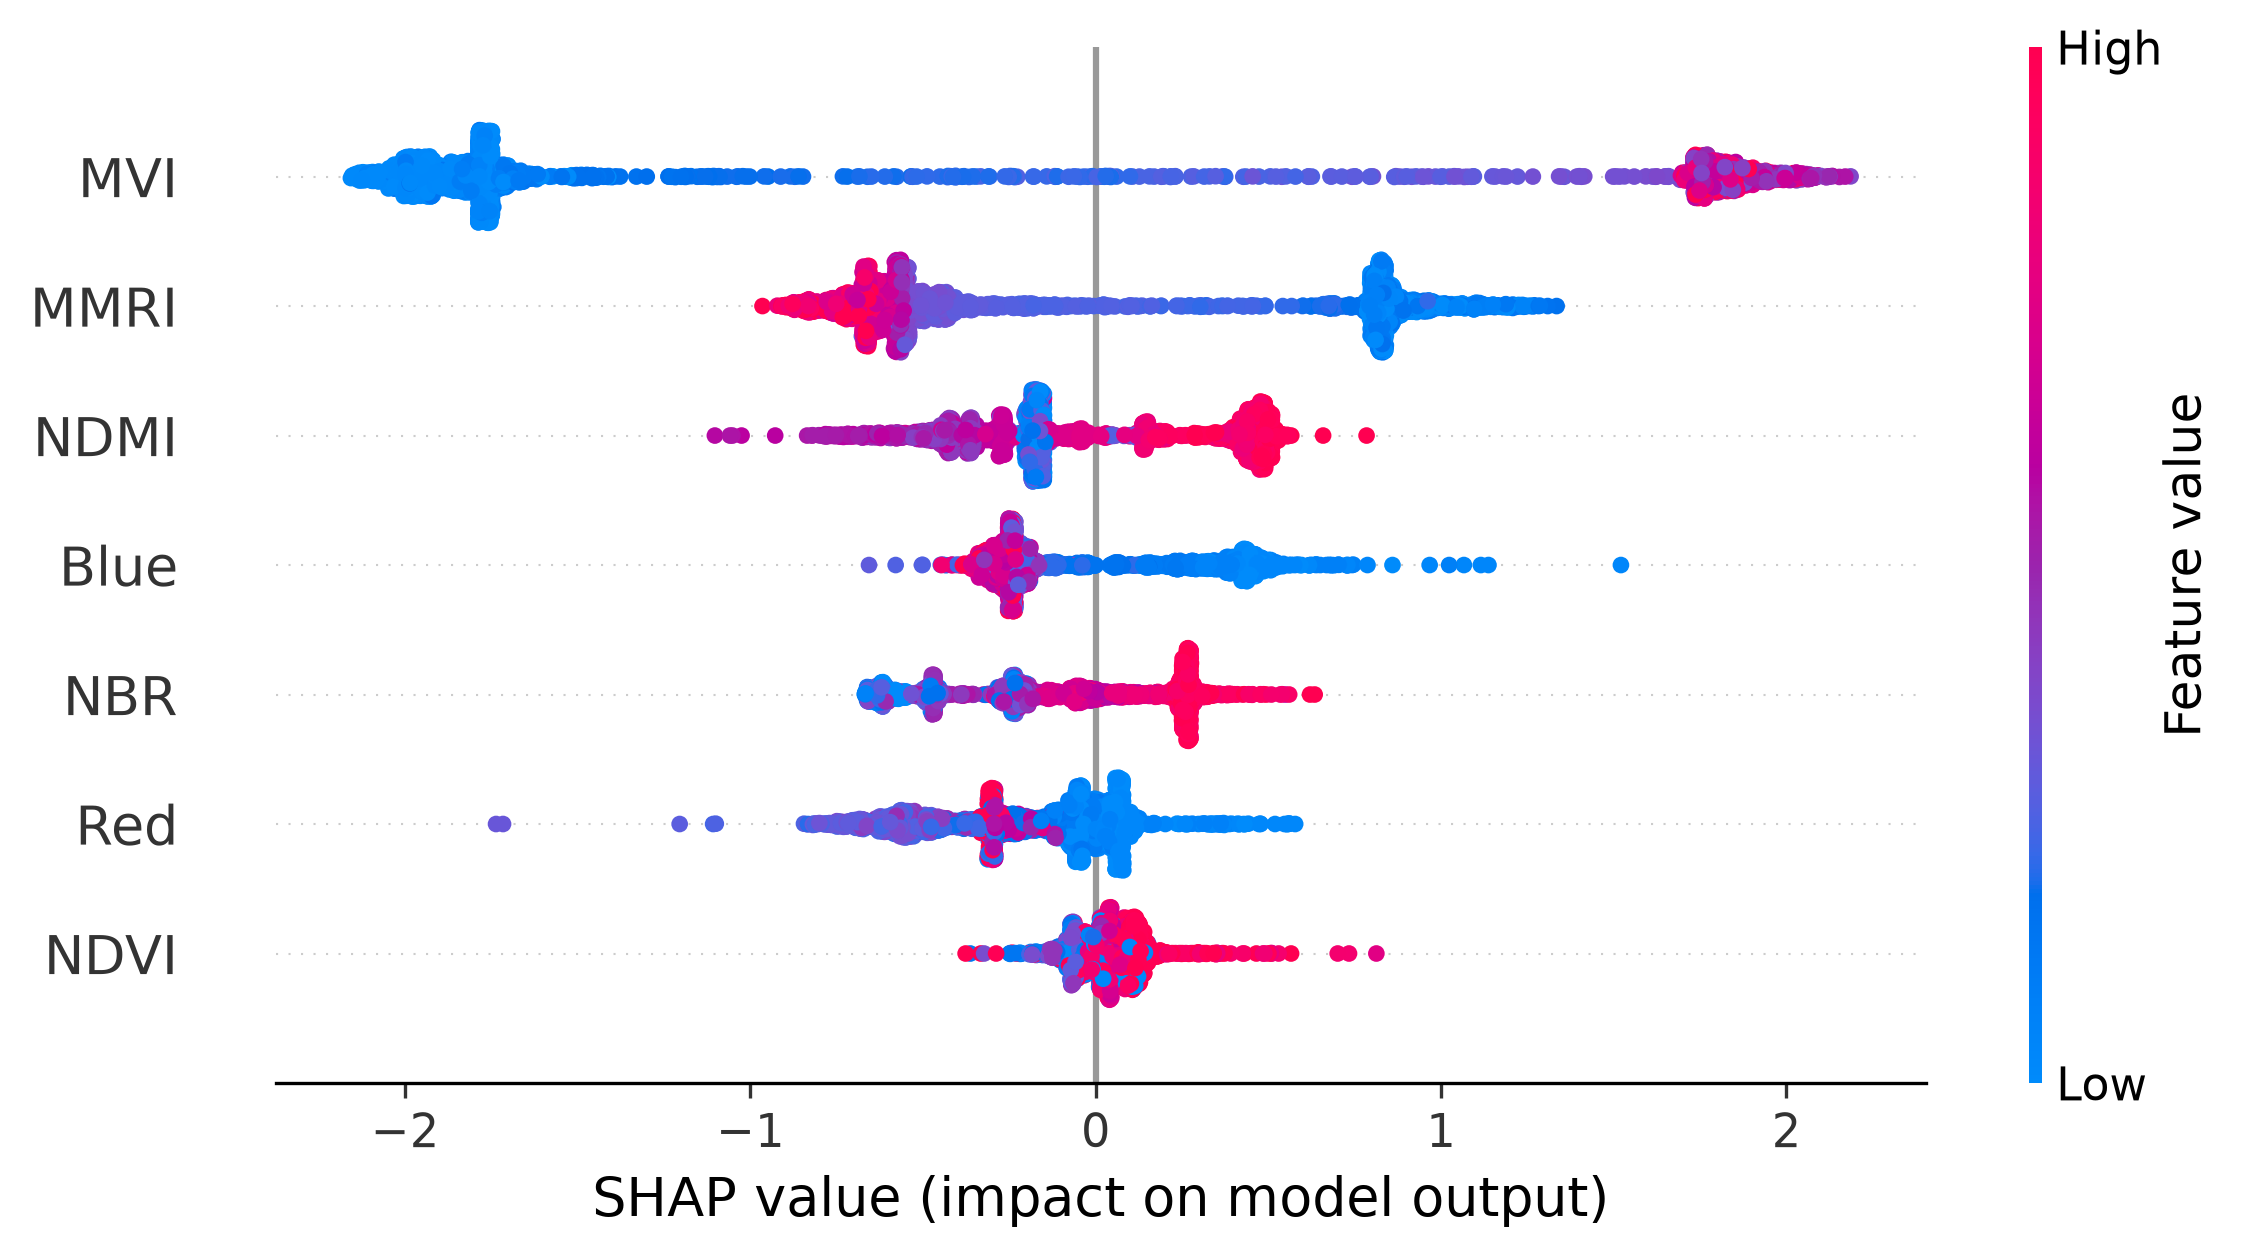

In [35]:
shap_mng_dir = os.path.join(interp_dir, "shap_mangroves")
_ = cf.calc_shap_feature_contributions(
    cls_cfg,
    xgb_sel_mdl,
    train_file,
    feature_cols=sel_feats,
    target_class="mangroves",
    use_tree_explainer=True,
    subsample_n_smpls=3000,
    rnd_seed=rnd_seed,
    shap_summary_plot=os.path.join(shap_mng_dir, "shap_summary_mangroves.png"),
    shap_scatter_plots_dir=shap_mng_dir,
)
display(Image(filename=os.path.join(shap_mng_dir, "shap_summary_mangroves.png"), width=700))

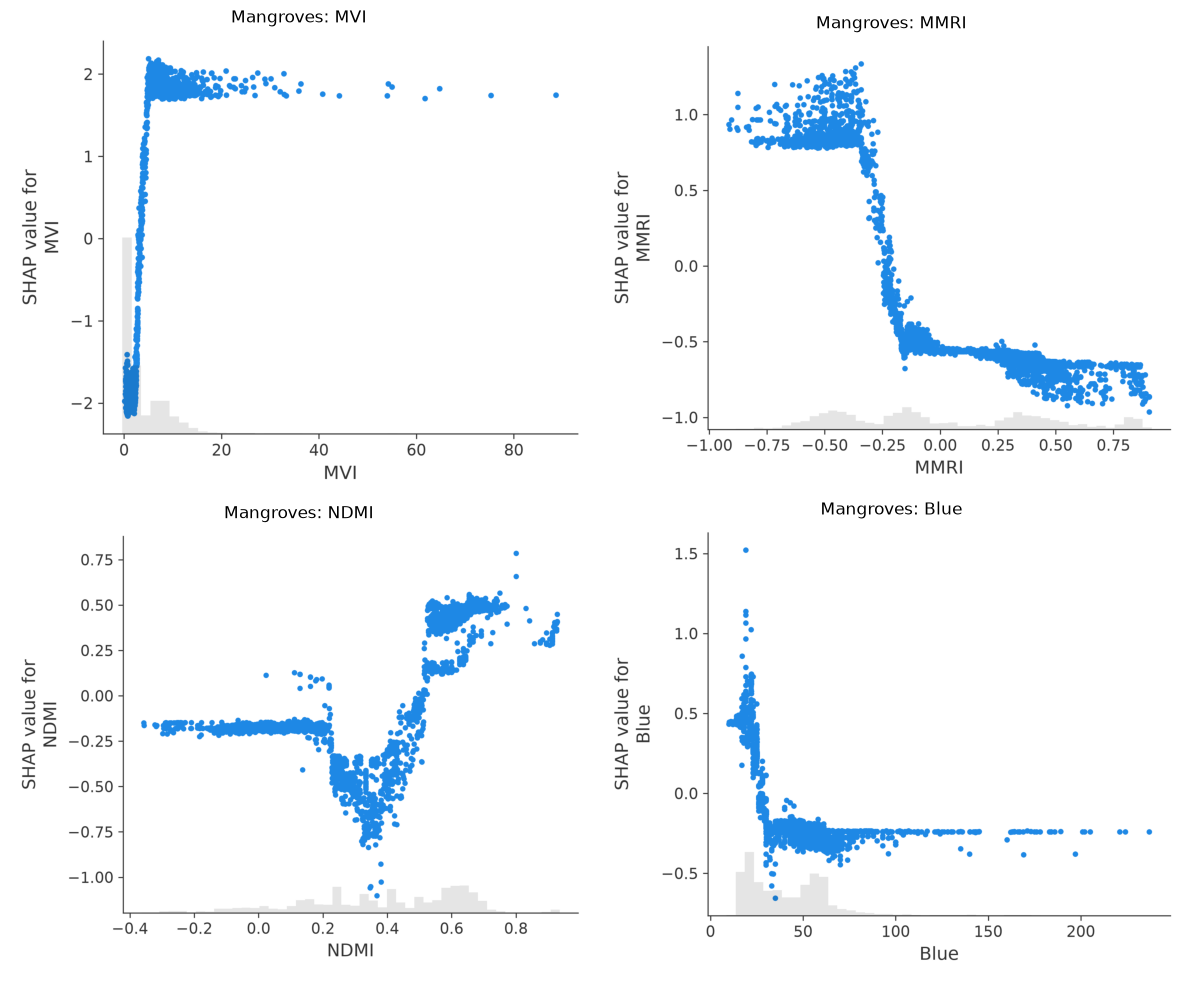

In [36]:
top_mng_feats = shap_df.sort_values("mean_abs_shap_mangroves", ascending=False)["feature"].tolist()[:4]

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
for ax, feat in zip(axs.flatten(), top_mng_feats):
    ax.imshow(plt.imread(os.path.join(shap_mng_dir, f"shap_scatter_{feat}.png")))
    ax.set_title(f"Mangroves: {feat}")
    ax.axis("off")
plt.tight_layout()
plt.show()

Reading the mangrove plots:

* **MVI:** a sharp step. Pixels with MVI below about 3 get SHAP values around −2 (strongly not mangrove); above about 5 they get around +2. Above 5 the value makes no further difference (MVI = 10 or 80 is treated the same). The model has learnt an MVI threshold between about 3 and 5.
* **MMRI:** the opposite direction. MMRI below about −0.3 pushes towards mangroves (+0.8 to +1.2), above about −0.2 away from them (−0.5 to −1).
* **NDMI:** above about 0.5 pushes towards mangroves (+0.4 to +0.5). Values between about 0.25 and 0.45 push *away* from mangroves more strongly than lower values do: this is the range where the wetter terrestrial vegetation and water (whose NDMI is high because the SWIR reflectance of water is close to zero) overlap.
* **Blue:** very low blue reflectance (below about 0.028) pushes towards mangroves. Mangrove canopies are dark in the visible bands, but this is also a feature which could pick up local atmospheric or illumination differences (see section 11.5).

The SHAP values are on the log-odds scale, so a contribution of +2 multiplies the odds of the mangrove class by about e² ≈ 7.

### 10.3 Sobol Sensitivity Analysis (SALib)

Sobol sensitivity analysis (Sobol', 2001; Saltelli, 2002), here with [SALib](https://salib.readthedocs.io) (Herman & Usher, 2017), treats the model as a black-box function of its inputs. It samples the inputs across their ranges (a quasi-random Saltelli sample), predicts the probability of one class for each sample, and decomposes the variance of that probability into contributions from each feature:

* **S1 (first order):** the fraction of the variance explained by the feature on its own.
* **ST (total order):** the fraction explained by the feature *including all its interactions* with other features. **ST − S1** therefore measures how much the feature acts through interactions.
* **S2 (second order):** the fraction explained by the interaction of a pair of features.

Each index has a bootstrap confidence interval (`_conf`); indices smaller than their confidence interval cannot be distinguished from zero.

**An important caveat:** the Sobol sample treats every feature as **independent and uniformly distributed** between its minimum and maximum. Real spectral features are not independent: e.g., a pixel cannot have a high NDVI and a very low MVI, as both depend on NIR. Many of the sampled "pixels" are therefore physically impossible, and the indices describe the model's behaviour over this unrealistic input space, not only over real pixels. Removing redundant features (section 6) makes this less severe, which is another benefit of feature selection, but it does not remove the problem.

The bounds are the minimum and maximum of the samples given. Because MVI has extreme values (section 3.1), using the full range would mean most of the samples have MVI values which hardly occur in the image. The training samples are therefore trimmed to the 1st – 99th percentile of each feature first.

In [37]:
train_q = train_df[sel_feats].quantile([0.01, 0.99])
in_range = ((train_df[sel_feats] >= train_q.loc[0.01]) & (train_df[sel_feats] <= train_q.loc[0.99])).all(axis=1)
interp_df = train_df[in_range]
print(f"{len(interp_df)} of {len(train_df)} training samples are within the 1st - 99th percentile of every feature")
print(interp_df["class_name"].value_counts().to_dict())

32772 of 36000 training samples are within the 1st - 99th percentile of every feature
{'other_terrestrial': 11172, 'mangroves': 10841, 'water': 10759}


In [38]:
sobol_st, sobol_s1, sobol_s2 = dict(), dict(), dict()
for cls_name in class_info:
    st_df, s1_df, s2_df = cf.calc_salib_feature_sensitivity(
        cls_cfg,
        xgb_sel_mdl,
        interp_df,
        feature_cols=sel_feats,
        target_class=cls_name,
        n_samples=1024,
        sobol_plot_file=os.path.join(interp_dir, f"sobol_{cls_name}.png"),
        sobol_overall_file=os.path.join(interp_dir, f"sobol_total_{cls_name}.csv"),
        sobol_first_file=os.path.join(interp_dir, f"sobol_first_{cls_name}.csv"),
        sobol_second_file=os.path.join(interp_dir, f"sobol_second_{cls_name}.csv"),
        rnd_seed=rnd_seed,
    )
    sobol_st[cls_name], sobol_s1[cls_name], sobol_s2[cls_name] = st_df, s1_df, s2_df

Blue Range:	(15.0 - 143.0)
Red Range:	(16.0 - 247.0)
NDVI Range:	(-0.48076921701431274 - 0.8913043737411499)
NDMI Range:	(-0.24814264476299286 - 0.8947368264198303)
NBR Range:	(-0.1439252346754074 - 0.9237056970596313)
MVI Range:	(0.3888888955116272 - 22.615385055541992)
MMRI Range:	(-0.7414075136184692 - 0.868852436542511)


Blue Range:	(15.0 - 143.0)
Red Range:	(16.0 - 247.0)
NDVI Range:	(-0.48076921701431274 - 0.8913043737411499)
NDMI Range:	(-0.24814264476299286 - 0.8947368264198303)
NBR Range:	(-0.1439252346754074 - 0.9237056970596313)
MVI Range:	(0.3888888955116272 - 22.615385055541992)
MMRI Range:	(-0.7414075136184692 - 0.868852436542511)


Blue Range:	(15.0 - 143.0)
Red Range:	(16.0 - 247.0)
NDVI Range:	(-0.48076921701431274 - 0.8913043737411499)
NDMI Range:	(-0.24814264476299286 - 0.8947368264198303)
NBR Range:	(-0.1439252346754074 - 0.9237056970596313)
MVI Range:	(0.3888888955116272 - 22.615385055541992)
MMRI Range:	(-0.7414075136184692 - 0.868852436542511)


(The ranges printed above are the bounds of the Sobol sample.) The total-order (ST) and first-order (S1) indices for each class, and the difference ST − S1:

In [39]:
sobol_tbl = pandas.concat(
    {
        cls_name: pandas.DataFrame({
            "S1": sobol_s1[cls_name]["S1"],
            "ST": sobol_st[cls_name]["ST"],
            "ST_conf": sobol_st[cls_name]["ST_conf"],
            "ST-S1": sobol_st[cls_name]["ST"] - sobol_s1[cls_name]["S1"],
        })
        for cls_name in class_info
    },
    axis=1,
)
sobol_tbl.round(3)

mangroves                       other_terrestrial                        water                      
                S1     ST ST_conf  ST-S1                S1     ST ST_conf  ST-S1     S1     ST ST_conf  ST-S1
variable                                                                                                     
Blue         0.036  0.055   0.008  0.020             0.001  0.007   0.003  0.007  0.020  0.044   0.006  0.024
Red          0.022  0.119   0.021  0.097             0.033  0.101   0.025  0.068  0.040  0.080   0.017  0.040
NDVI         0.100  0.365   0.049  0.266             0.343  0.631   0.065  0.288  0.667  0.801   0.062  0.134
NDMI         0.196  0.359   0.042  0.163             0.202  0.413   0.051  0.210 -0.000  0.043   0.008  0.044
NBR          0.015  0.057   0.011  0.042             0.018  0.064   0.012  0.046 -0.004  0.007   0.002  0.011
MVI          0.093  0.127   0.022  0.035             0.025  0.062   0.015  0.037  0.006  0.030   0.007  0.024
MMRI         0.281  0.352   0.033  0.071             0.039  0.096   0.017  0.057  0.116  0.199   0.025  0.084

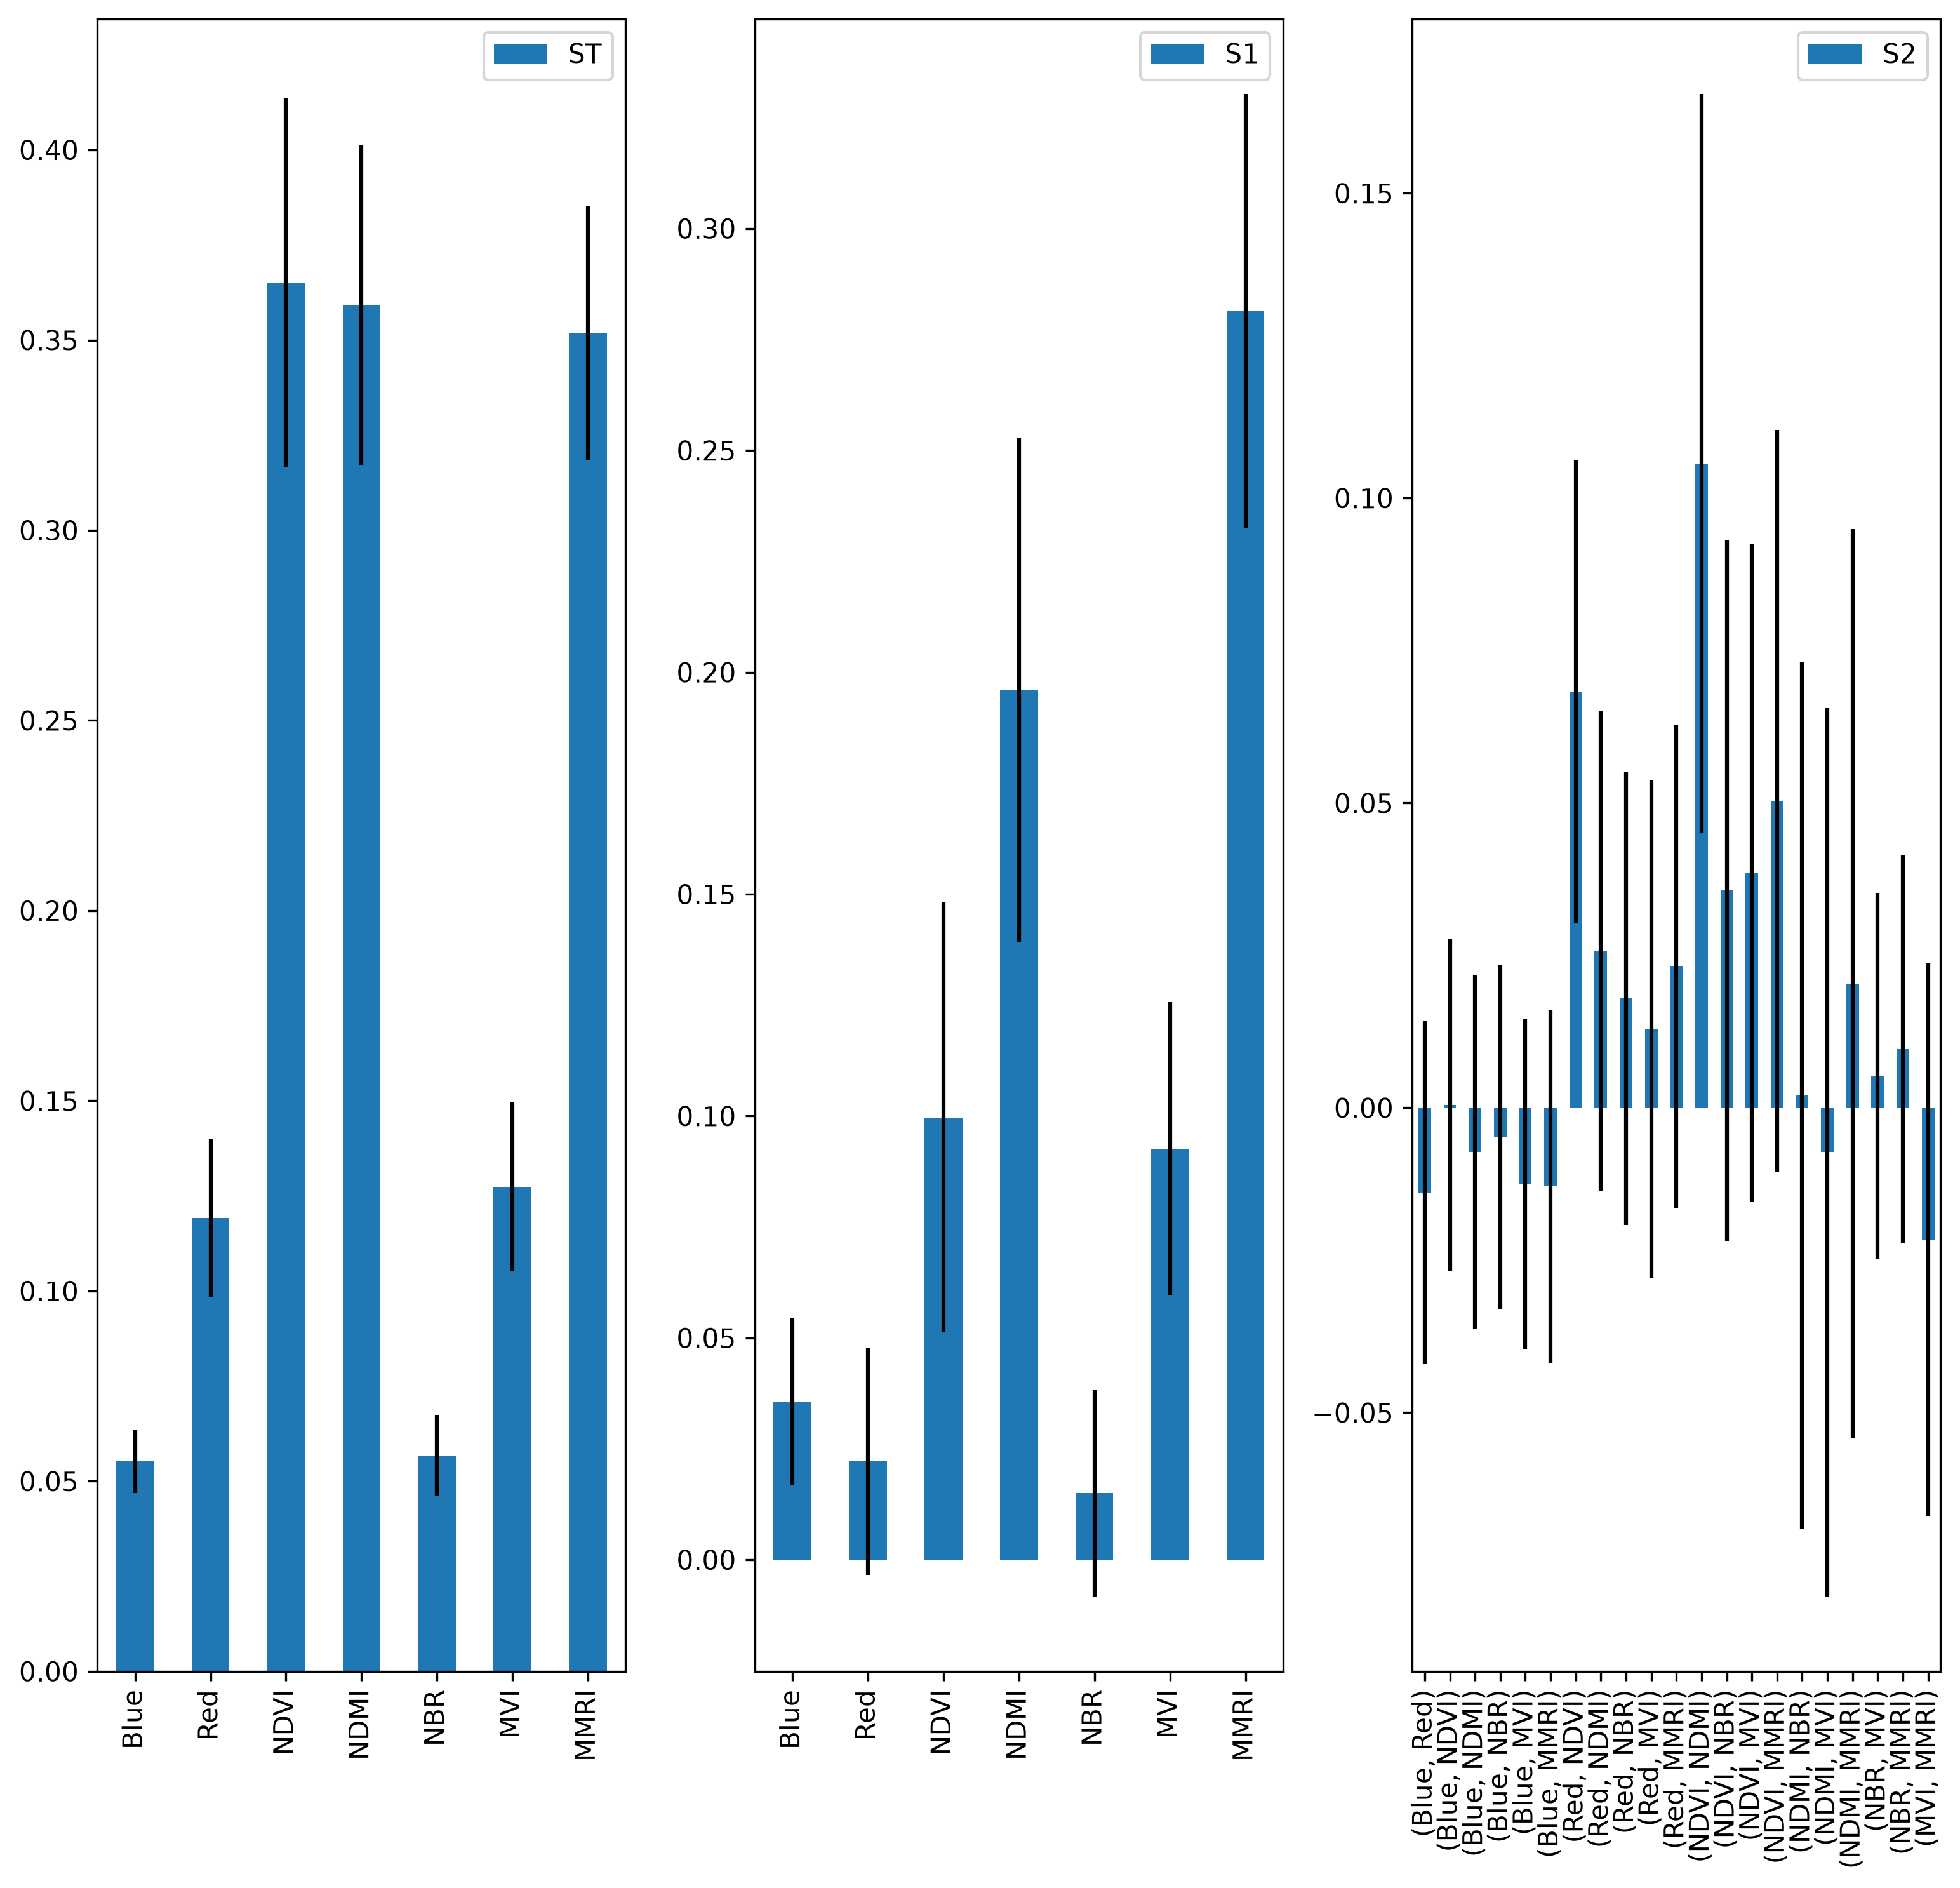

In [40]:
display(Image(filename=os.path.join(interp_dir, "sobol_mangroves.png"), width=800))

The second-order indices for mangroves, largest first (only the pairs whose index is larger than its confidence interval are clearly non-zero):

In [41]:
s2_mng = sobol_s2["mangroves"].copy()
s2_mng["clearly_non_zero"] = s2_mng["S2"] > s2_mng["S2_conf"]
s2_mng.sort_values("S2", ascending=False).head(8).round(3)

S2  S2_conf  clearly_non_zero
variable_1 variable_2                                  
NDVI       NDMI        0.106    0.061              True
Red        NDVI        0.068    0.038              True
NDVI       MMRI        0.050    0.061             False
           MVI         0.039    0.054             False
           NBR         0.036    0.057             False
Red        NDMI        0.026    0.039             False
           MMRI        0.023    0.040             False
NDMI       MMRI        0.020    0.075             False

For **water**, NDVI alone explains two thirds of the variance of the water probability (S1 = 0.67), with MMRI second: a simple, almost additive model. For **other terrestrial** and **mangroves** the picture is more complicated:

* For mangroves, the largest first-order index is MMRI (S1 = 0.28), followed by NDMI (0.20), NDVI (0.10) and MVI (0.09).
* NDVI has the largest *total* index for mangroves (ST = 0.37) but a small S1 (0.10): most of its effect comes through interactions (ST − S1 = 0.27). The clearly non-zero second-order indices are NDVI × NDMI (0.11) and Red × NDVI (0.07). Physically this makes sense: a high NDMI only indicates a wet mangrove canopy if the pixel is vegetated (high NDVI); over water NDMI is also high.
* MVI has a modest Sobol index (ST = 0.13), despite being the most important mangrove feature by SHAP. Its effect is a step between about 3 and 5 (section 10.2), and the Sobol sample spreads MVI uniformly between 0.4 and 22.6, so most of the samples are on the flat part above the step, where MVI makes no difference. The Sobol index depends on the sampled range as much as on the model.

The S2 confidence intervals are wide for most pairs; only two pairs are clearly different from zero.

### 10.4 Feature Response Curves

A response curve shows how the predicted class probabilities change as one feature is varied across its range while all the other features are held at a fixed value. This is similar to a partial dependence plot, except that the other features are fixed at one summary value rather than averaged over the data. We use the **median** (`summary_stat="median"`), which is less affected by skewed features such as MVI than the mean, and the trimmed samples from section 10.3 so the curves span the 1st – 99th percentile of each feature.

The same caveat as for Sobol applies: holding the other features at their medians while one feature varies creates combinations which may not exist (e.g., the median NDVI with a water-like MVI). The curves are most trustworthy where the classes actually have samples, so the 5th – 95th percentile range of the training samples of each class is drawn below the curves.

In [42]:
resp_df = cf.calc_feature_response_curves(
    cls_cfg,
    xgb_sel_mdl,
    interp_df,
    feature_cols=sel_feats,
    n_samples=100,
    summary_stat="median",
    out_file=os.path.join(interp_dir, "response_curves.csv"),
    response_plots_dir=os.path.join(interp_dir, "response_curves"),
    use_pbar=False,
)

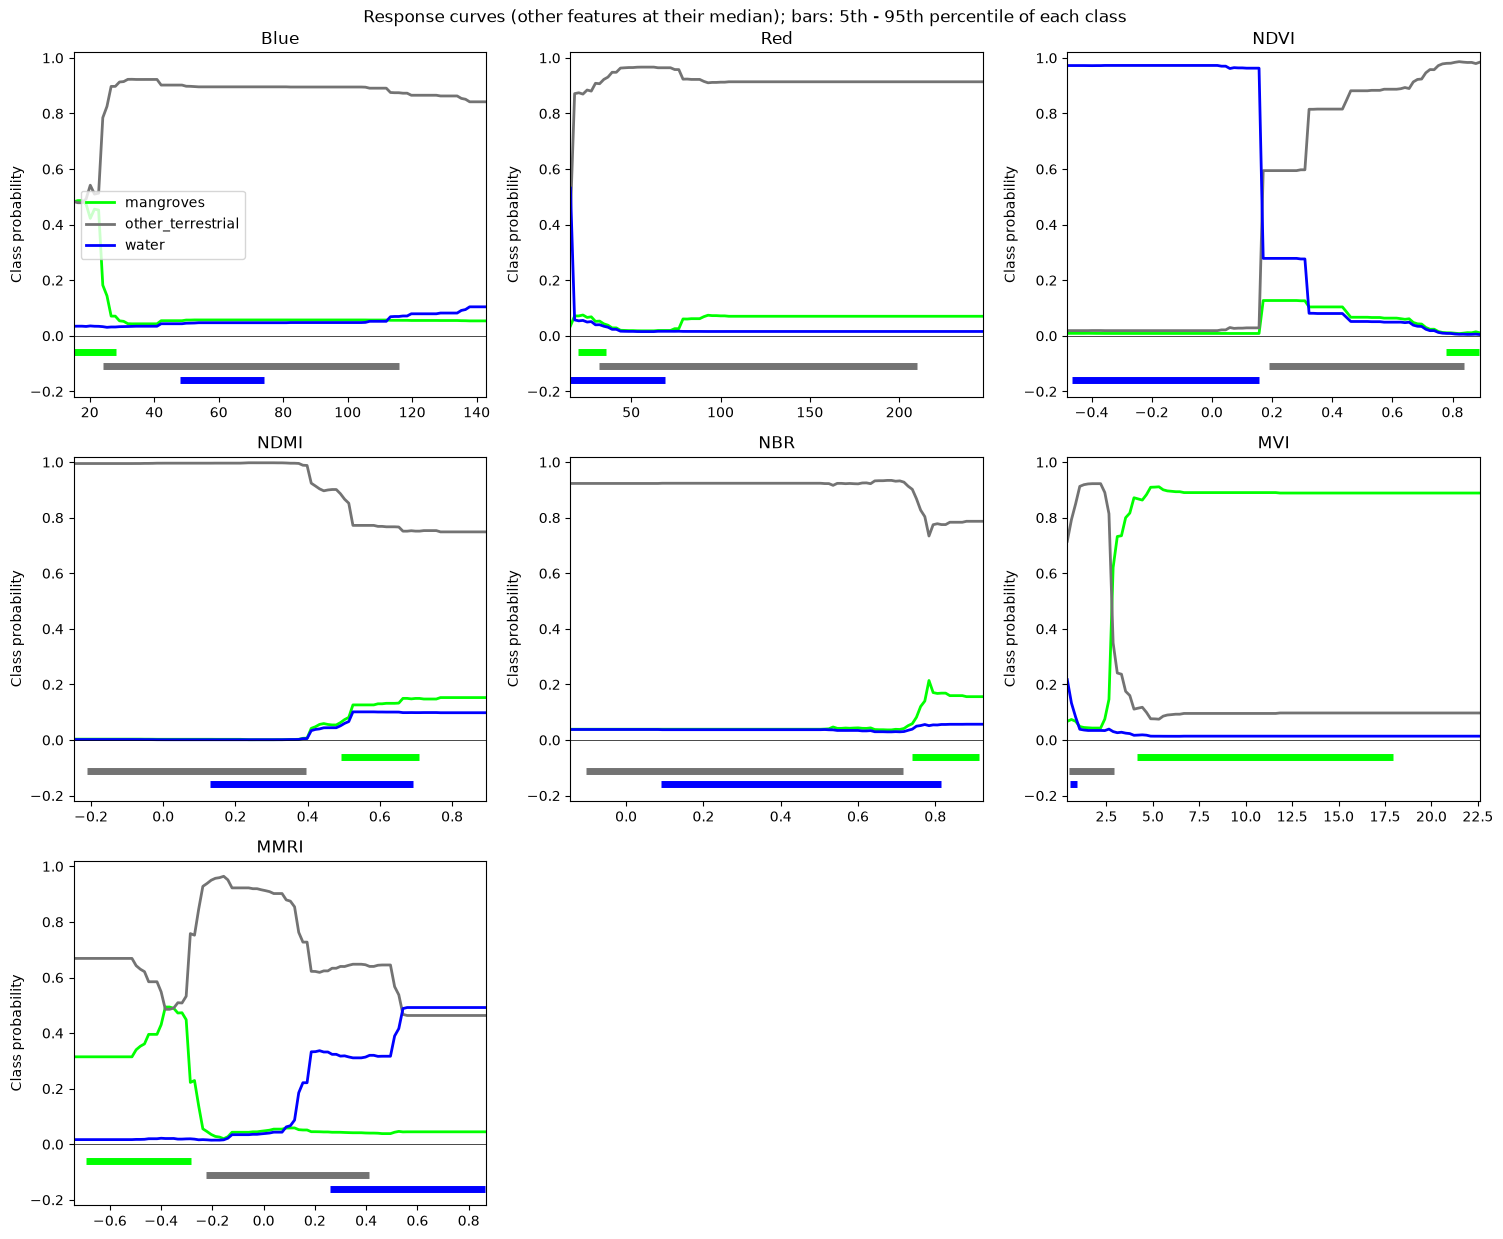

In [43]:
cls_names = list(class_info.keys())
# The class colours are stored as hexadecimal strings, which matplotlib
# understands. The light grey of the Other-Terrestrial class is hard to see
# on a white background, so use a darker grey for the plots.
cls_clrs = {name: cls.colour for name, cls in class_info.items()}
cls_clrs["other_terrestrial"] = "#737373"

n_cols = 3
n_rows = int(numpy.ceil(len(sel_feats) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(15, 4.2 * n_rows))
for ax, feat in zip(axs.flatten(), sel_feats):
    for cls_name in cls_names:
        ax.plot(resp_df[f"{feat}_vals"], resp_df[f"{feat}_{cls_name}_prob"],
                color=cls_clrs[cls_name], lw=2, label=cls_name)
    # The 5th - 95th percentile of the training samples of each class.
    for i, cls_name in enumerate(cls_names):
        p05, p95 = train_df.loc[train_df["class_name"] == cls_name, feat].quantile([0.05, 0.95])
        ax.plot([p05, p95], [-0.06 - 0.05 * i] * 2, color=cls_clrs[cls_name], lw=5, solid_capstyle="butt")
    ax.set_xlim(resp_df[f"{feat}_vals"].min(), resp_df[f"{feat}_vals"].max())
    ax.set_ylim(-0.22, 1.02)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(feat)
    ax.set_ylabel("Class probability")
for ax in axs.flatten()[len(sel_feats):]:
    ax.axis("off")
axs.flatten()[0].legend(loc="center left")
fig.suptitle("Response curves (other features at their median); bars: 5th - 95th percentile of each class")
plt.tight_layout()
plt.show()

Because all the other features are held at the median of the (trimmed) training samples of *all* the classes, the "starting" pixel for each curve is not a typical member of any class (its MVI of about 1.6 is typical of other terrestrial). This explains why several curves are dominated by other terrestrial. The most informative curves are:

* **MVI:** the mangrove probability rises from below 0.1 to about 0.9 between MVI ≈ 2.5 and ≈ 5, and the other terrestrial probability falls correspondingly, matching the SHAP step. This one feature is enough to flip the "median pixel" from other terrestrial to mangroves. The step lies between the 95th percentile of other terrestrial and the 5th percentile of mangroves, i.e., in the gap between the classes.
* **MMRI:** three regimes, matching the class ranges: mangroves below about −0.3, other terrestrial from about −0.2 to 0.4, water above about 0.5.
* **NDVI:** water below about 0.17, land above. The other terrestrial probability increases with NDVI because the other features say "not mangrove" at the median point; NDVI alone cannot make a pixel a mangrove.
* **NDMI, NBR:** high values (above about 0.45 and 0.75) increase the mangrove (and water) probability a little; on their own, from the median pixel, they cannot overcome the other features.
* **Blue, Red:** the mangrove probability is only raised at the very lowest values, where the mangrove samples are; otherwise these curves are flat.

The flat parts of the curves outside the class bars (e.g., MVI above 18) are extrapolation: tree models predict a constant beyond the data they were trained on.

## 11. Interpretation

### 11.1 Summary Table

The table brings the measures together for the mangrove class (the permutation importance is for all the classes together, as it measures the overall accuracy).

In [44]:
summary_df = pandas.DataFrame(index=sel_feats)
summary_df["perm_rank"] = perm_imp_df.set_index("feature")["rank"]
mng_shap = shap_df.set_index("feature")["mean_abs_shap_mangroves"]
summary_df["shap_mng_mean_abs"] = mng_shap
summary_df["shap_mng_rank"] = mng_shap.rank(ascending=False).astype(int)
summary_df["sobol_mng_S1"] = sobol_s1["mangroves"]["S1"]
summary_df["sobol_mng_ST"] = sobol_st["mangroves"]["ST"]
summary_df["sobol_mng_ST_rank"] = summary_df["sobol_mng_ST"].rank(ascending=False).astype(int)
summary_df.sort_values("shap_mng_rank").round(3)

,perm_rank,shap_mng_mean_abs,shap_mng_rank,sobol_mng_S1,sobol_mng_ST,sobol_mng_ST_rank
MVI,4,1.775,1,0.093,0.127,4
MMRI,5,0.665,2,0.281,0.352,3
NDMI,2,0.333,3,0.196,0.359,2
Blue,6,0.292,4,0.036,0.055,7
NBR,7,0.286,5,0.015,0.057,6
Red,3,0.234,6,0.022,0.119,5
NDVI,1,0.077,7,0.100,0.365,1


Bringing the numbers together with the response curves and SHAP plots:

| Feature | Permutation rank (all classes) | Mean \|SHAP\| rank (mangroves) | Sobol ST (mangroves) | Response-curve shape (mangroves) | Physical interpretation |
|---|---|---|---|---|---|
| MVI | 4 | 1 | 0.13 | Sharp step up between ≈ 2.5 and 5, flat above | Greenness relative to SWIR1 moisture; the key mangrove vs terrestrial separator |
| MMRI | 5 | 2 | 0.35 | High below ≈ −0.3, low above | Vegetation signal stronger than the water signal, with a wet (high MNDWI) background |
| NDMI | 2 | 3 | 0.36 | Small rise above ≈ 0.45 | Canopy water content, but only meaningful for vegetated pixels (interacts with NDVI) |
| Blue | 6 | 4 | 0.06 | Raised only at the lowest values | Dark canopy in the visible; possibly also scene-specific |
| NBR | 7 | 5 | 0.06 | Small rise above ≈ 0.75 | Moisture / structure (SWIR2); largely redundant with NDMI |
| Red | 3 | 6 | 0.12 | Raised only at the lowest values | Chlorophyll absorption (dense canopy) |
| NDVI | 1 | 7 | 0.37 | Low everywhere (land vs water switch at ≈ 0.17) | "Is it vegetated?": separates water from land, not mangroves from other vegetation |

### 11.2 Agreement Between the Measures

The three measures give quite different rankings, and the differences are informative rather than contradictory:

* **Permutation importance** measures the loss of *overall* accuracy, across all three classes. NDVI comes first because without it the model cannot tell water from land, which affects a third of the test samples. Features that share information (MVI and MMRI) look less important because the model can fall back on the other one.
* **SHAP** measures the contribution to each class's output on *real* samples. For the mangrove output it ranks MVI first by a large margin and NDVI last, which matches what we know about the classes: every vegetated pixel has a high NDVI, so NDVI cannot help decide whether a vegetated pixel is a mangrove.
* **Sobol** measures the contribution to the variance of the mangrove probability over a *uniformly sampled*, largely unrealistic, input space. It rewards features whose effect is spread across their whole range and which interact with others (NDVI, NDMI, MMRI), and penalises features whose effect is concentrated in a narrow part of their range (MVI).

They agree on the main point: the mangrove decision depends on **MVI, MMRI and NDMI** (moisture and water-related indices), with NDVI acting as a gate between water and land. For a question like "what makes the model call a pixel a mangrove?", the SHAP results on real samples are the most directly relevant.

### 11.3 The Variables

Checking each variable against the physical expectations of section 3:

* **MVI** (Baloloy et al., 2020) behaves exactly as intended: high values (strong NIR relative to green, low SWIR1 relative to green) indicate mangroves. The model uses it as a threshold between about 3 and 5, separating the mangrove samples (5th percentile 4.2) from the other terrestrial samples (95th percentile 2.9). ✔
* **MMRI** (Diniz et al., 2019): negative values (|NDVI| > |MNDWI|, with a relatively high MNDWI for vegetation) indicate mangroves, values near zero other terrestrial land, and positive values water. This is consistent with the index's design. ✔
* **NDMI**: high values push towards mangroves, consistent with high canopy water content. But the relationship is not monotonic: water also has a high NDMI (median 0.42), because both its NIR and SWIR1 reflectance are close to zero. NDMI therefore only indicates canopy moisture in combination with NDVI, which is the NDVI × NDMI interaction found by Sobol. ✔ (with an interaction)
* **NDVI**: separates water (NDVI below ≈ 0.17) from land, as expected, and contributes almost nothing to the mangrove decision. ✔
* **NBR**: a weak positive effect at high values, in the same direction as NDMI; most of its information is already in NDMI and MVI. Expected direction, but little added value.
* **Red and Blue**: low visible reflectance pushes towards mangroves, consistent with dense, dark mangrove canopies. These raw bands are the features most likely to be affected by haze or illumination; see the next sections.

### 11.4 Mangroves vs Other Terrestrial, and Water vs Land

* **Water vs land** is decided by NDVI, with MMRI as a second, partly independent signal. This is the easy part of the problem: every model classifies the water test samples perfectly.
* **Mangroves vs other terrestrial land** is decided by **MVI**, then **MMRI** and **NDMI**, i.e., by features that combine greenness with SWIR1-based moisture and water signals. This is the scientifically interesting result: the model distinguishes mangroves from terrestrial vegetation by their wetness (wet canopy and substrate), not by their greenness. This matches the reasoning behind the mangrove-specific indices.

Almost all the errors in the confusion matrix are between the two vegetated classes (45 mangrove pixels predicted as other terrestrial and 32 the other way); only 3 mangrove pixels were predicted as water.

### 11.5 Anything Suspicious?

Two checks on the testing samples: how the model handles the mangrove pixels with extreme (negative) MVI values, and what the misclassified pixels look like.

In [45]:
test_df["pred_name"] = id_to_name.loc[xgb_sel_mdl.predict(test_df[sel_feats])].values
mng_test = test_df[test_df["class_name"] == "mangroves"]

# Mangrove pixels with a negative MVI.
neg_mvi = mng_test[mng_test["MVI"] < 0]
print(f"Mangrove test pixels with MVI < 0: {len(neg_mvi)}; predicted as {neg_mvi['pred_name'].value_counts().to_dict()}")
print("Their median Green and SWIR1 reflectance (x1000):", neg_mvi[["Green", "SWIR1"]].median().to_dict())

# Median feature values of the correct and the misclassified pixels of the
# two vegetated classes.
err_tbl = test_df[test_df["class_name"] != "water"].copy()
err_tbl["result"] = numpy.where(err_tbl["class_name"] == err_tbl["pred_name"], "correct", "wrong")
err_tbl.groupby(["class_name", "result"])[sel_feats].median().round(2).assign(
    n=err_tbl.groupby(["class_name", "result"]).size()
)

Mangrove test pixels with MVI < 0: 5; predicted as {'mangroves': 5}
Their median Green and SWIR1 reflectance (x1000): {'Green': 42.0, 'SWIR1': 39.0}


Blue   Red  NDVI  NDMI   NBR   MVI  MMRI     n
class_name        result                                                 
mangroves         correct  20.0  23.0  0.86  0.62  0.85  8.16 -0.47  3952
                  wrong    25.0  33.0  0.83  0.42  0.74  3.04 -0.22    48
other_terrestrial correct  38.0  65.5  0.66  0.17  0.46  1.58 -0.10  3968
                  wrong    21.0  28.0  0.86  0.46  0.75  3.54 -0.25    32

* **MVI is unstable for the darkest, wettest canopies.** MVI = (NIR − green) / (SWIR1 − green), so when SWIR1 is almost equal to green the denominator approaches zero and MVI jumps to very large positive *or negative* values. About 90 of the 12,000 mangrove training samples have MVI below 0 or above 50; they are dense mangrove pixels (NDVI ≈ 0.85) whose SWIR1 reflectance is as dark as their green reflectance. A negative MVI would push a pixel *away* from mangroves, which is physically wrong. The model copes: the mangrove test pixels with a negative MVI are all classified correctly, thanks to MMRI (≈ −0.9) and NDMI. This is a property of the index, not of the training data, and it is a good example of why it helps to keep more than one feature carrying the same information. A bounded version of the index, or clipping MVI, would be more robust.
* **The misclassified pixels sit on the learnt thresholds.** The wrongly classified mangrove and other terrestrial pixels have medians of MVI ≈ 3.0 – 3.5, NDMI ≈ 0.42 – 0.46 and MMRI ≈ −0.22 to −0.25, exactly at the transitions in the SHAP and response-curve plots, while the correctly classified pixels are well on either side. These are genuinely ambiguous pixels (e.g., mixed pixels, sparse or stressed mangroves, or wet terrestrial vegetation), not a sign of a broken model.
* **Blue and Red.** The model uses very low visible reflectance as evidence for mangroves. This is physically plausible (dense canopies), but the mangrove training polygons cover a narrow range of Blue values (5th – 95th percentile ≈ 0.015 – 0.028). If the training polygons happen to be in a clearer part of the scene than the terrestrial ones, the model could be partly learning the atmosphere rather than the land cover. With so little weight (mean |SHAP| ≈ 0.3) this does not drive the classification, but it is worth checking with training polygons spread across the scene, or by removing the raw bands and comparing.
* **No dependence on the extreme tails.** The SHAP and response plots are flat above MVI ≈ 5 and at very high Red and Blue values, so the outliers in the data do not affect the predictions.

### 11.6 Limitations and Next Steps

* **Random pixel split:** the training, validation and testing pixels come from the same polygons, so the accuracies (and the differences between the models) are optimistic. A polygon-grouped split (`group_col`) would give a more honest comparison.
* **One date, one scene:** the relationships the model has learnt (e.g., the MVI threshold) depend on this scene's atmosphere, tide and phenology. Applying the model to another date (as the change detection notebooks do) assumes the relationships still hold.
* **Three broad classes:** "Other-Terrestrial" mixes forest, agriculture, bare soil and urban areas; a finer legend would make the mangrove vs terrestrial forest question sharper.
* **Correlated features:** the Sobol indices and the response curves evaluate the model on combinations of feature values which do not occur. SHAP (on real samples) and permutation importance (on real test samples) are less affected, which is why the interpretation leans on them.
* **Optimisation budget:** 30 trials is small; more trials (and a cross-validated score) would give more stable parameters.

**Things to try:** split the samples by polygon and see how the three models compare; add a second date (e.g., a low-tide image) as extra features; replace MVI with CMRI or MMRI and see whether the model finds an equally good mangrove feature; use more Optuna trials.

## 12. Summary

* Eleven spectral indices were calculated for a Landsat 5 TM scene, each chosen for a property of mangroves (greenness, canopy moisture, wet substrate, water). Several are almost perfectly correlated with each other.
* Feature selection on the training samples only: VIF removed 10 of the 17 features as redundant; BorutaShap and RFECV both kept the remaining seven (Blue, Red, NDVI, NDMI, NBR, MVI and MMRI).
* An XGBoost classifier was optimised with Optuna (30 trials) and trained on the selected features. Its test accuracy (99.3 %) is the same as that of a bands-only model and an all-features model: on this easy, randomly split test set, the indices did not improve the accuracy, but they gave a smaller and more interpretable model.
* `apply_xgboost_multiclass_classifier` matches the model's stored feature names to the configuration's bands, so the same configuration works for models trained on different feature subsets.
* Permutation importance, SHAP, Sobol sensitivity and response curves answer different questions and give different rankings. Together they show that NDVI separates water from land, while MVI (with a threshold between ≈ 3 and 5), MMRI and NDMI separate mangroves from other terrestrial vegetation by their wetness, consistent with the physical rationale of the indices.
* Sobol indices and response curves evaluate the model on unrealistic combinations of correlated features, and depend on the sampled ranges; SHAP on real samples is the most direct explanation of the model's decisions.
* MVI becomes unstable (very large positive or negative values) for dark, wet canopies where SWIR1 ≈ green; the model copes because MMRI and NDMI carry similar information.

### References

* Baloloy, A.B., Blanco, A.C., Sta. Ana, R.R.C. & Nadaoka, K. (2020). Development and application of a new mangrove vegetation index (MVI) for rapid and accurate mangrove mapping. *ISPRS Journal of Photogrammetry and Remote Sensing*, 166, 95–117.
* Bunting, P., Rosenqvist, A., Lucas, R.M., Rebelo, L.-M., Hilarides, L., Thomas, N., Hardy, A., Itoh, T., Shimada, M. & Finlayson, C.M. (2018). The Global Mangrove Watch — a new 2010 global baseline of mangrove extent. *Remote Sensing*, 10(10), 1669.
* Chen, T. & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.
* Diniz, C., Cortinhas, L., Nerino, G., Rodrigues, J., Sadeck, L., Adami, M. & Souza-Filho, P.W.M. (2019). Brazilian mangrove status: three decades of satellite data analysis. *Remote Sensing*, 11(7), 808.
* Feyisa, G.L., Meilby, H., Fensholt, R. & Proud, S.R. (2014). Automated Water Extraction Index: a new technique for surface water mapping using Landsat imagery. *Remote Sensing of Environment*, 140, 23–35.
* Gao, B.-C. (1996). NDWI — a normalized difference water index for remote sensing of vegetation liquid water from space. *Remote Sensing of Environment*, 58(3), 257–266.
* Gupta, K., Mukhopadhyay, A., Giri, S., Chanda, A., Datta Majumdar, S., Samanta, S., Mitra, D., Samal, R.N., Pattnaik, A.K. & Hazra, S. (2018). An index for discrimination of mangroves from non-mangroves using LANDSAT 8 OLI imagery. *MethodsX*, 5, 1129–1139.
* Guyon, I., Weston, J., Barnhill, S. & Vapnik, V. (2002). Gene selection for cancer classification using support vector machines. *Machine Learning*, 46, 389–422.
* Herman, J. & Usher, W. (2017). SALib: an open-source Python library for sensitivity analysis. *Journal of Open Source Software*, 2(9), 97.
* Huete, A.R. (1988). A soil-adjusted vegetation index (SAVI). *Remote Sensing of Environment*, 25(3), 295–309.
* Huete, A., Didan, K., Miura, T., Rodriguez, E.P., Gao, X. & Ferreira, L.G. (2002). Overview of the radiometric and biophysical performance of the MODIS vegetation indices. *Remote Sensing of Environment*, 83(1–2), 195–213.
* Key, C.H. & Benson, N.C. (2006). Landscape assessment (LA): sampling and analysis methods. In *FIREMON: Fire Effects Monitoring and Inventory System*, USDA Forest Service General Technical Report RMRS-GTR-164-CD, LA-1–LA-51.
* Kursa, M.B. & Rudnicki, W.R. (2010). Feature selection with the Boruta package. *Journal of Statistical Software*, 36(11), 1–13.
* Lundberg, S.M. & Lee, S.-I. (2017). A unified approach to interpreting model predictions. In *Advances in Neural Information Processing Systems 30*, 4765–4774.
* Lundberg, S.M., Erion, G., Chen, H., DeGrave, A., Prutkin, J.M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N. & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2, 56–67.
* McFeeters, S.K. (1996). The use of the Normalized Difference Water Index (NDWI) in the delineation of open water features. *International Journal of Remote Sensing*, 17(7), 1425–1432.
* Rouse, J.W., Haas, R.H., Schell, J.A. & Deering, D.W. (1974). Monitoring vegetation systems in the Great Plains with ERTS. In *Third Earth Resources Technology Satellite-1 Symposium*, NASA SP-351, 309–317.
* Saltelli, A. (2002). Making best use of model evaluations to compute sensitivity indices. *Computer Physics Communications*, 145(2), 280–297.
* Sobol', I.M. (2001). Global sensitivity indices for nonlinear mathematical models and their Monte Carlo estimates. *Mathematics and Computers in Simulation*, 55(1–3), 271–280.
* Wilson, E.H. & Sader, S.A. (2002). Detection of forest harvest type using multiple dates of Landsat TM imagery. *Remote Sensing of Environment*, 80(3), 385–396.
* Xu, H. (2006). Modification of normalised difference water index (NDWI) to enhance open water features in remotely sensed imagery. *International Journal of Remote Sensing*, 27(14), 3025–3033.